# 07 · Final model, impact and SHAP (Gate 2) - the one fair test

From S4 until now I kept the test months (Jan-May 2023, 1,767 tenders) locked. I treated them like a sealed exam paper.

In this section I:
1. Write down my final plan first: which methods, which settings and which scores I will use.
2. Open the test answers only once and score every method together.
3. Report whatever comes out, good or bad. I do not go back and change anything.
4. Use SHAP to explain the final model, so I can show why a tender gets high risk.
5. Write a model card. This is a one-page summary of the model.

| Part | Steps | What I do |
|---|---|---|
| A | 1-5 | Lock my plan before I look at any test answer |
| B | 6-9 | Give every test tender a risk score from each method (still no answers) |
| C | 10-16 | Open the answers once and check how each method did |
| D | 17-20 | Explain the final model with SHAP |
| E | 21-23 | Model card, save the files, and extra checks |

Three choices I made before building:

| Choice | What I picked | Why |
|---|---|---|
| A | Embeddings learn from all tenders whose bids were opened before 1 Jan 2023 | In January an auditor would use every old tender whose answer is already known |
| B | SHAP explains the final app model | The app will show only one model, so I explain that one |
| C | Bands: top 20% High, next 30% Medium, bottom 50% Low | High is the 20% an auditor can check first, same as in S5 and S6 |

# Part A · Lock my plan before I look

## Step 1 · Libraries and version check

In [1]:
# pandas = tables, numpy = maths helpers
import pandas as pd
import numpy as np

In [2]:
# matplotlib = charts, os = folders
import matplotlib.pyplot as plt
import os

In [3]:
# Let Python look one folder up, where tenderlens_style.py lives
import sys
sys.path.append("..")

In [4]:
# My colours and chart helpers with the short name ts
import tenderlens_style as ts

In [5]:
# Logistic Regression = our simple weighted-score model; Scaler = puts clues on the same size scale
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [6]:
# Scores: PR-AUC, ROC-AUC, and the confusion table (right and wrong flags)
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix

In [7]:
# shap = explains each risk score; joblib = saves a model to a file
import shap
import joblib

In [8]:
# We make many charts in this notebook, so switch off the "too many charts open" warning
plt.rcParams["figure.max_open_warning"] = 0

In [9]:
# IPython display = show text as nice markdown (for the model card)
from IPython.display import Markdown
from IPython.display import display

In [10]:
# Version check: numpy must be 1.26.4 and shap 0.46.0 (we fixed these on 15 Oct)
import sklearn
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("shap:", shap.__version__)
print("all ok")

numpy: 1.26.4
pandas: 3.0.5
scikit-learn: 1.9.0
shap: 0.46.0
all ok


## Step 2 · Load the data (only counts, no test answers yet)

In [11]:
# The clue table from S5 (one row = one labelled tender, 34 clues)
lab = pd.read_csv("../data/processed/features_split_v2.csv", parse_dates=["published_date"])
lab.shape

(6790, 46)

In [12]:
# The full clean table from S2 (we only need the bid opening date and the cleaned title)
df = pd.read_csv("../data/interim/tenders_clean.csv", parse_dates=["published_date", "bid_opening_date"])
df.shape

(39411, 39)

In [13]:
# Add bid_opening_date (day the bids were opened) and title_key (cleaned title) to every tender
lab = lab.merge(df[["tender_id", "title_key", "bid_opening_date"]], on="tender_id", how="left")
lab.shape

(6790, 48)

In [14]:
# The S6 text clues file: we only need work_type (roads, buildings, health ...)
text_clues = pd.read_csv("../data/processed/s6_text_clues.csv")
lab = lab.merge(text_clues[["tender_id", "work_type"]], on="tender_id", how="left")
lab.shape

(6790, 49)

In [15]:
# One text column, same as S6: the title, plus the description only when it adds something new
same_desc = lab["title"] == lab["work_description"]
lab["text"] = np.where(same_desc, lab["title"], lab["title"] + " " + lab["work_description"])

In [16]:
# Every tender has a bid opening date? (0 = none missing)
missing_open = lab["bid_opening_date"].isna().sum()
print("Missing bid opening dates:", missing_open)

Missing bid opening dates: 0


In [17]:
# How many tenders in each split (counts only - we do NOT look at the test single-bid rate yet)
lab["split"].value_counts()

split
train    2753
val      2270
test     1767
Name: count, dtype: int64

In [18]:
# The 7 base clues from S4 (built step by step, one line each)
base = ["dept_rate", "log_value", "value_missing"]
base = base + ["bid_window_days", "months_to_fy_end"]
base = base + ["same_day_lot", "retender_60d"]
len(base)

7

In [19]:
# Short, easy names for the clues (for charts and SHAP)
nice = {}
nice["dept_rate"] = "Department's past single-bid rate"
nice["log_value"] = "Tender value (log)"
nice["value_missing"] = "Value not written"
nice["bid_window_days"] = "Days to submit bids"
nice["months_to_fy_end"] = "Months to financial year end"
nice["same_day_lot"] = "Lot posted the same day"
nice["retender_60d"] = "Re-tender within 60 days"

## Step 3 · The locked plan (written before I look at test)

In [20]:
# Empty list, one row per method
plan = []

In [21]:
# Method 1: random checking (the auditor picks tenders by chance)
row = {}
row["method"] = "Random checking"
row["what it is"] = "Every tender gets a random score (seed 42), plus the average of 500 random draws"
row["learns from"] = "Nothing"
row["role"] = "Benchmark"
plan.append(row)

In [22]:
# Method 2: Rule B from S5 (no model, just a simple rule)
row = {}
row["method"] = "Rule B: re-tender then dept"
row["what it is"] = "Quick re-tenders first, then by the department's past single-bid rate"
row["learns from"] = "Training department rates only (S4)"
row["role"] = "Benchmark"
plan.append(row)

In [23]:
# Method 3: our main model (the intended real use)
row = {}
row["method"] = "LogReg 7 clues, monthly"
row["what it is"] = "Logistic Regression on the 7 base clues, retrained at the start of every month"
row["learns from"] = "Only tenders whose bids were opened before that month (opened only rule)"
row["role"] = "Main model (app + SHAP)"
plan.append(row)

In [24]:
# Method 4: embeddings (the best fair text method from S6)
row = {}
row["method"] = "Embeddings alone"
row["what it is"] = "Logistic Regression on 384 MiniLM meaning numbers of the title + description"
row["learns from"] = "Train + validation tenders opened before 1 Jan 2023, learned once"
row["role"] = "Comparison"
plan.append(row)

In [25]:
# The plan as a table
plan_table = pd.DataFrame(plan)
plan_table

,method,what it is,learns from,role
0,Random checking,"Every tender gets a random score (seed 42), pl...",Nothing,Benchmark
1,Rule B: re-tender then dept,"Quick re-tenders first, then by the department...",Training department rates only (S4),Benchmark
2,"LogReg 7 clues, monthly","Logistic Regression on the 7 base clues, retra...",Only tenders whose bids were opened before tha...,Main model (app + SHAP)
3,Embeddings alone,Logistic Regression on 384 MiniLM meaning numb...,Train + validation tenders opened before 1 Jan...,Comparison


In [26]:
# Settings we promise to use (one line each)
settings = {}
settings["scores"] = "PR-AUC, ROC-AUC, capture top 10/20/30%, lift, precision top 50/100/200"
settings["auditor view"] = "Auditor checks the riskiest 20% of test tenders"
settings["risk bands"] = "High = top 20%, Medium = next 30%, Low = bottom 50%"
settings["bootstrap"] = "500 re-draws, seed 42: main vs Random, main vs Rule B, embeddings vs Random"
settings["test months"] = "Jan, Feb, Mar, Apr-May 2023 (tenders dated before 2023 go with January)"
settings["rule"] = "Score test ONCE. No new candidates after looking."
settings["locked at"] = str(pd.Timestamp.now().round("s"))

In [27]:
# Settings as a small table
settings_table = pd.DataFrame(list(settings.items()), columns=["setting", "value"])
settings_table

,setting,value
0,scores,"PR-AUC, ROC-AUC, capture top 10/20/30%, lift, ..."
1,auditor view,Auditor checks the riskiest 20% of test tenders
2,risk bands,"High = top 20%, Medium = next 30%, Low = botto..."
3,bootstrap,"500 re-draws, seed 42: main vs Random, main vs..."
4,test months,"Jan, Feb, Mar, Apr-May 2023 (tenders dated bef..."
5,rule,Score test ONCE. No new candidates after looking.
6,locked at,2026-10-16 15:09:39


In [28]:
# Save the plan and the settings together in one file (the proof)
os.makedirs("../reports", exist_ok=True)
plan_out = pd.concat([plan_table, settings_table], ignore_index=True)
plan_path = "../reports/s7_locked_plan.csv"
if os.path.exists(plan_path):
    print("Locked plan was already saved before test was opened - kept as it is")
else:
    plan_out.to_csv(plan_path, index=False)
    print("Locked plan saved")

Locked plan was already saved before test was opened - kept as it is


## Step 4 · The test months (counts only)

In S4, a few tenders shared a reference number with a later tender, so I moved them forward into test. That is why some test tenders are dated in 2022.

I score these early tenders together with January, the same way I did in S5 and S6.

In [29]:
# Scoring month of every tender (year-month as text, e.g. "2023-01")
lab["score_month"] = lab["published_date"].dt.to_period("M").astype(str)

In [30]:
# Test tenders dated before 2023 are scored with January
early = (lab["split"] == "test") & (lab["published_date"] < "2023-01-01")
lab.loc[early, "score_month"] = "2023-01"
print("Test tenders dated before 2023 (go with January):", early.sum())

Test tenders dated before 2023 (go with January): 232


In [31]:
# Month names for charts: April and May together (May has very few tenders)
month_names = {}
month_names["2023-01"] = "Jan 2023"
month_names["2023-02"] = "Feb 2023"
month_names["2023-03"] = "Mar 2023"
month_names["2023-04"] = "Apr-May 2023"
month_names["2023-05"] = "Apr-May 2023"

In [32]:
# The train, validation and test tables
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]
test = lab[lab["split"] == "test"].copy()

In [33]:
# Month name column for test
test["month_name"] = test["score_month"].map(month_names)

In [34]:
# How many test tenders in each month (counts only)
month_order = ["Jan 2023", "Feb 2023", "Mar 2023", "Apr-May 2023"]
month_counts = test["month_name"].value_counts().reindex(month_order)
month_counts

month_name
Jan 2023        842
Feb 2023        485
Mar 2023        355
Apr-May 2023     85
Name: count, dtype: int64

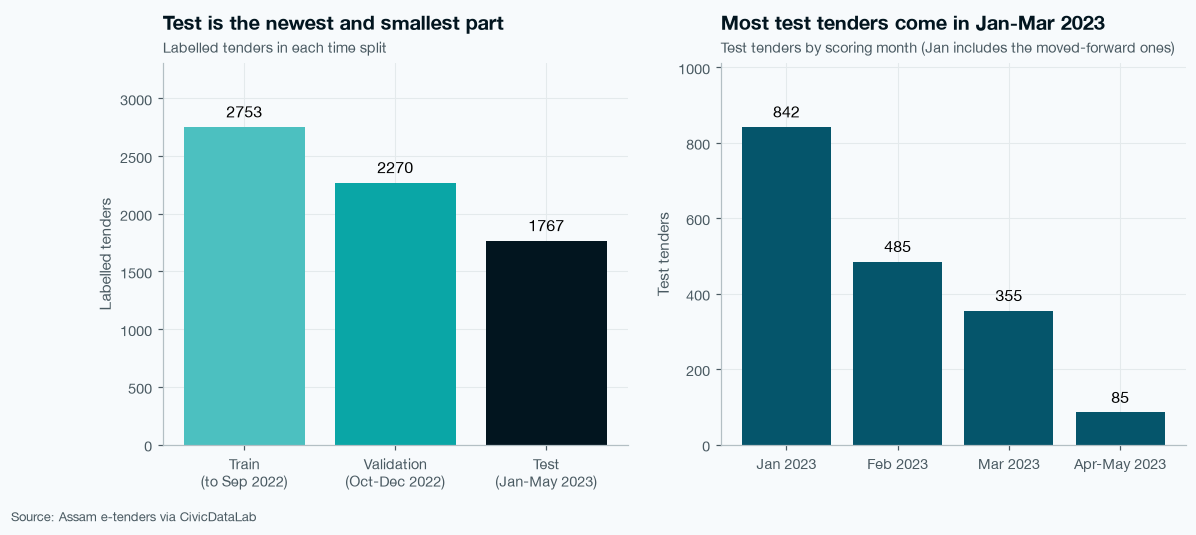

In [35]:
# Chart S7a: left = tenders in each split, right = test tenders in each month
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: train, validation, test sizes (teal ramp, light to dark = old to new)
split_counts = lab["split"].value_counts().reindex(["train", "val", "test"])
split_labels = ["Train\n(to Sep 2022)", "Validation\n(Oct-Dec 2022)", "Test\n(Jan-May 2023)"]
b1 = axes[0].bar(split_labels, split_counts.values, color=[ts.BLUES[2], ts.BLUES[3], ts.BLUES[5]])
axes[0].bar_label(b1, padding=4)
axes[0].set_ylim(0, split_counts.max() * 1.2)
axes[0].set_ylabel("Labelled tenders")
ts.title(axes[0], "Test is the newest and smallest part", subtitle="Labelled tenders in each time split")

# Right: test tenders per scoring month
b2 = axes[1].bar(month_counts.index, month_counts.values, color=ts.BLUES[4])
axes[1].bar_label(b2, padding=4)
axes[1].set_ylim(0, month_counts.max() * 1.2)
axes[1].set_ylabel("Test tenders")
ts.title(axes[1], "Most test tenders come in Jan-Mar 2023", subtitle="Test tenders by scoring month (Jan includes the moved-forward ones)")

# Source line
ts.source(fig)

In [36]:
# Make sure the folder exists, then save the chart
os.makedirs("../reports/figures", exist_ok=True)
ts.save_fig(fig, "../reports/figures/S7a_test_months.png")

## Step 5 · Turn the test texts into embeddings (MiniLM)

Embeddings: the MiniLM model reads the text of a tender and turns it into 384 numbers that hold its meaning. Two texts that mean the same thing get similar numbers.

I already made these numbers for train and validation in S6. Here I make them for the 1,767 test texts once and save them in a file.

| Code | What it does |
|---|---|
| `SentenceTransformer("all-MiniLM-L6-v2")` | loads the MiniLM model (it is already on my Mac) |
| `.encode(texts)` | gives 384 meaning numbers for each text |
| `normalize_embeddings=True` | makes every row the same size, so only the meaning matters |
| `np.save` / `np.load` | saves the numbers to a file / reads them back |

In [37]:
# The sentence embedding library (installed on 15 Oct)
from sentence_transformers import SentenceTransformer

In [38]:
# Train + validation meaning numbers from S6 (same row order as train + validation in lab)
tv = lab[lab["split"] != "test"]
emb_tv = np.load("../data/processed/s6_embeddings_train_val.npy")
emb_tv.shape

(5023, 384)

In [39]:
# Where we keep the meaning numbers for the test texts
emb_test_path = "../data/processed/s7_embeddings_test.npy"

In [40]:
# If the file is already there, load it; if not, run MiniLM once and save the file
if os.path.exists(emb_test_path):
    emb_test = np.load(emb_test_path)
    print("Loaded saved test embeddings")
else:
    st_model = SentenceTransformer("all-MiniLM-L6-v2")
    emb_test = st_model.encode(list(test["text"]), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    np.save(emb_test_path, emb_test)
    print("Made and saved test embeddings")
emb_test.shape

Loaded saved test embeddings


(1767, 384)

In [41]:
# Column names e0, e1, ... e383
emb_cols = []
for i in range(emb_tv.shape[1]):
    emb_cols.append("e" + str(i))

In [42]:
# Put the meaning numbers in two tables, with the same row labels as tv and test
emb_tv_table = pd.DataFrame(emb_tv, index=tv.index, columns=emb_cols)
emb_test_table = pd.DataFrame(emb_test, index=test.index, columns=emb_cols)

In [43]:
# Stack them and glue them onto lab (every tender now has 384 meaning columns)
emb_all = pd.concat([emb_tv_table, emb_test_table])
lab = lab.join(emb_all)
lab.shape

(6790, 435)

In [44]:
# Make train, validation, tv and test again, now with the meaning columns
train = lab[lab["split"] == "train"]
val = lab[lab["split"] == "val"]
tv = lab[lab["split"] != "test"]
test = lab[lab["split"] == "test"].copy()
test["month_name"] = test["score_month"].map(month_names)
print("Test:", test.shape)

Test: (1767, 436)


# Part B · Give every test tender a risk score (still no answers)

In this part each method gives every test tender a risk score. I still do not look at any test answer.

One thing to note: from February onwards, the main model also learns from January test tenders whose bids are already opened. This is what would happen in real life, because by February those answers are known. I only check how well it did in Part C.

## Step 6 · Random checking

In [45]:
# Random: every test tender gets a random risk (seed 42, same as S5 and S6)
rng = np.random.default_rng(42)
test["risk_random"] = rng.random(len(test))

## Step 7 · Rule B: quick re-tenders first, then department rate

In [46]:
# Rule B: re-tender (0 or 1) counts most, department rate breaks the ties
test["risk_ruleb"] = test["retender_60d"] + test["dept_rate"] / 10

In [47]:
# How many test tenders are quick re-tenders (they go to the top of Rule B's list)
retender_count = int(test["retender_60d"].sum())
print("Quick re-tenders in test:", retender_count)

Quick re-tenders in test: 90


## Step 8 · Main model: LogReg on 7 clues, retrained every month (opened only)

How this would work in real life: on the 1st of every month, the auditor trains the model again and then scores that month's new tenders.

The "opened only" rule (from S6): the model can only learn from tenders whose bids were opened before that 1st. If the bids are still sealed, we do not know the answer yet, so that tender cannot be used.

I first write out January step by step. Then I use a small helper to do the same for the other months.

In [48]:
# January: the first day of January and of February
start = pd.Timestamp("2023-01-01")
end = pd.Timestamp("2023-02-01")

In [49]:
# The tenders we score in January
score = test[test["score_month"] == "2023-01"]
len(score)

842

In [50]:
# Learn only from tenders whose bids were opened before 1 January
learn = lab[lab["bid_opening_date"] < start]

In [51]:
# Never learn from a tender we are scoring this month (safety line)
learn = learn[~learn["tender_id"].isin(score["tender_id"])]
print("January learns from:", len(learn), "tenders")

January learns from: 4576 tenders


In [52]:
# 1. The scaler learns the size of each clue from the learning tenders
scaler = StandardScaler()
scaler.fit(learn[base])

StandardScaler()

In [53]:
# 2. The model (balanced = single-bid tenders count more, because they are fewer)
model = LogisticRegression(class_weight="balanced", max_iter=3000)

In [54]:
# 3. Learn from the scaled clues and the answers
model.fit(scaler.transform(learn[base]), learn["single_bid"])

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [55]:
# 4. Risk score (0 to 1) for every January tender
jan_risk = model.predict_proba(scaler.transform(score[base]))[:, 1]
jan_risk[:5].round(3)

array([0.355, 0.453, 0.424, 0.448, 0.439])

Now I put steps 1 to 4 into one helper, so I can reuse it for any month and any list of clues.

In [56]:
# Helper 1: scale, train Logistic Regression, return risk scores
def lr_risk(learn, score, clues):
    scaler = StandardScaler()
    scaler.fit(learn[clues])
    model = LogisticRegression(class_weight="balanced", max_iter=3000)
    model.fit(scaler.transform(learn[clues]), learn["single_bid"])
    return model.predict_proba(scaler.transform(score[clues]))[:, 1]

In [57]:
# The 5 scoring months
months = ["2023-01", "2023-02", "2023-03", "2023-04", "2023-05"]

In [58]:
# Empty risk column and an empty list for the learning sizes
test["risk_main"] = 0.0
learn_rows = []

In [59]:
# Every month: learn from opened tenders only, then score that month's tenders
for month in months:
    start = pd.Timestamp(month + "-01")
    score = test[test["score_month"] == month]
    published_before = lab[lab["published_date"] < start]
    learn = lab[lab["bid_opening_date"] < start]
    learn = learn[~learn["tender_id"].isin(score["tender_id"])]
    test.loc[score.index, "risk_main"] = lr_risk(learn, score, base)
    row = {}
    row["month"] = month
    row["scored"] = len(score)
    row["learned from"] = len(learn)
    row["published but not opened yet"] = int((published_before["bid_opening_date"] >= start).sum())
    learn_rows.append(row)

In [60]:
# How many learning tenders each month, and how many we had to leave out (bids still sealed)
learn_table = pd.DataFrame(learn_rows)
learn_table

,month,scored,learned from,published but not opened yet
0,2023-01,842,4576,472
1,2023-02,485,5632,235
2,2023-03,355,5996,356
3,2023-04,84,6538,168
4,2023-05,1,6788,1


In [61]:
# Check: the helper gives the same January scores as the step-by-step version (0.0 = same)
jan_gap = np.abs(test.loc[test["score_month"] == "2023-01", "risk_main"].values - jan_risk).max()
print("Biggest difference:", round(jan_gap, 6))

Biggest difference: 0.0


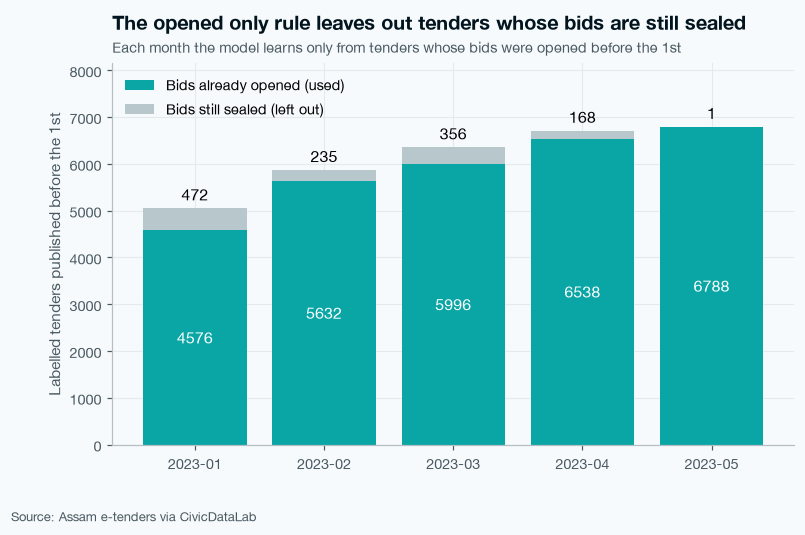

In [62]:
# Chart S7b: learning tenders each month - opened (used) and not opened yet (left out)
fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(learn_table["month"], learn_table["learned from"], color=ts.MULTI, label="Bids already opened (used)")
b2 = ax.bar(learn_table["month"], learn_table["published but not opened yet"], bottom=learn_table["learned from"], color=ts.NEUTRAL, label="Bids still sealed (left out)")

# Number labels
ax.bar_label(b1, label_type="center", color="white")
ax.bar_label(b2, padding=3)

# Axis names, room at the top, legend
ax.set_ylabel("Labelled tenders published before the 1st")
ax.set_ylim(0, (learn_table["learned from"] + learn_table["published but not opened yet"]).max() * 1.2)
ax.legend(loc="upper left")

# Title, subtitle, source
subtitle = "Each month the model learns only from tenders whose bids were opened before the 1st"
ts.title(ax, "The opened only rule leaves out tenders whose bids are still sealed", subtitle=subtitle)
ts.source(fig)

In [63]:
ts.save_fig(fig, "../reports/figures/S7b_opened_only_learning.png")

## Step 9 · Embeddings alone, learned once

In [64]:
# Learning tenders: train + validation tenders opened before 1 Jan 2023 (choice A)
learn_emb = tv[tv["bid_opening_date"] < "2023-01-01"]
print("Embeddings learn from:", len(learn_emb), "tenders")

Embeddings learn from: 4575 tenders


In [65]:
# Same helper, but the clues are the 384 meaning columns
test["risk_emb"] = lr_risk(learn_emb, test, emb_cols)

In [66]:
# The 4 methods: risk column -> name (one line each)
methods = {}
methods["risk_random"] = "Random checking"
methods["risk_ruleb"] = "Rule B: re-tender then dept"
methods["risk_main"] = "LogReg 7 clues, monthly"
methods["risk_emb"] = "Embeddings alone"

In [67]:
# Every method has one risk score for every test tender (no empty values)
test[list(methods.keys())].describe().round(3)

,risk_random,risk_ruleb,risk_main,risk_emb
count,1767.000,1767.000,1767.000,1767.000
mean,0.502,0.085,0.446,0.491
std,0.291,0.221,0.070,0.247
min,0.001,0.011,0.301,0.008
25%,0.243,0.026,0.420,0.292
50%,0.494,0.037,0.442,0.502
75%,0.764,0.044,0.473,0.694
max,0.999,1.046,0.757,0.990


### Insight · Locked plan and test set-up (Steps 1 to 9)

- Before looking at any test answer, I wrote down the 4 methods, the settings and the scores, and saved them in s7_locked_plan.csv with the date and time. This is my proof that I did not change the plan after seeing the results.
- Test has 1,767 tenders. 232 of them are dated in 2022 (moved forward in S4), so they are scored with January. January has 842 tenders, February 485, March 355 and April-May only 85.
- The main model is retrained at the start of every month and only learns from tenders whose bids were already opened. In January it learned from 4,576 tenders, and 472 tenders had to be left out because their bids were still sealed. By April it learned from 6,538 tenders.
- The helper gave exactly the same January scores as the step-by-step version (difference 0.0), so the monthly loop is correct.
- Embeddings learned once from 4,575 train and validation tenders whose bids were opened before 1 Jan 2023 (choice A).

# Part C · Open the test answers once and check everything

From here on I look at the test answers. Whatever comes out is my final result.

## Step 10 · Score all 4 methods

The scores I use:

| Score | What it means |
|---|---|
| PR-AUC | how well a method puts single-bid tenders at the top of the list (random checking gets about the single-bid rate) |
| ROC-AUC | 0.5 = no better than tossing a coin, 1.0 = perfect order |
| capture top 20% | if the auditor checks the riskiest 20% of tenders, how many of all single-bid tenders she finds (random = 20%) |
| lift top 20% | capture divided by 20. 1.0 = same as random, 1.2 = 20% better than random |
| precision top 100 | out of the 100 riskiest tenders, how many really got one bid |

In [68]:
# The real answers for test (1 = one bid, 0 = more than one)
y_te = test["single_bid"]
base_rate = y_te.mean() * 100
print("Test tenders:", len(test), "| single-bid:", int(y_te.sum()), "| rate:", round(base_rate, 1), "%")

Test tenders: 1767 | single-bid: 421 | rate: 23.8 %


In [69]:
# Helper 2: share (%) of all single-bid tenders found in the riskiest top part
def capture(y, risk, share):
    t = pd.DataFrame({"real": y.values, "risk": risk})
    t = t.sort_values("risk", ascending=False, kind="stable")
    top = t.head(int(len(t) * share))
    return top["real"].sum() / t["real"].sum() * 100

In [70]:
# Helper 3: share (%) of real single-bid tenders among the K riskiest
def precision_top(y, risk, k):
    t = pd.DataFrame({"real": y.values, "risk": risk})
    t = t.sort_values("risk", ascending=False, kind="stable")
    return t.head(k)["real"].mean() * 100

In [71]:
# Helper 4: all scores for one method as one row
def score_row(name, y, risk):
    row = {}
    row["method"] = name
    row["PR-AUC"] = round(average_precision_score(y, risk), 3)
    row["ROC-AUC"] = round(roc_auc_score(y, risk), 3)
    row["capture top 10%"] = round(capture(y, risk, 0.1), 1)
    row["capture top 20%"] = round(capture(y, risk, 0.2), 1)
    row["capture top 30%"] = round(capture(y, risk, 0.3), 1)
    row["lift top 20%"] = round(capture(y, risk, 0.2) / 20, 2)
    row["precision top 50"] = round(precision_top(y, risk, 50), 1)
    row["precision top 100"] = round(precision_top(y, risk, 100), 1)
    row["precision top 200"] = round(precision_top(y, risk, 200), 1)
    return row

In [72]:
# Score every method (one loop over the 4 risk columns)
results = []
for col in methods:
    results.append(score_row(methods[col], y_te, test[col].values))

In [73]:
# Random is luck, so also the average of 500 random draws (a fairer "random")
rng500 = np.random.default_rng(7)
draw_rows = []
for i in range(500):
    draw_rows.append(score_row("draw", y_te, rng500.random(len(test))))

In [74]:
# Average of the 500 draws as one row
draws = pd.DataFrame(draw_rows)
random_avg = draws.drop(columns="method").mean().round(3)
avg_row = {}
avg_row["method"] = "Random (average of 500 draws)"
avg_row.update(random_avg.to_dict())
results.append(avg_row)

In [75]:
# The results table
results_table = pd.DataFrame(results)
results_table

,method,PR-AUC,ROC-AUC,capture top 10%,capture top 20%,capture top 30%,lift top 20%,precision top 50,precision top 100,precision top 200
0,Random checking,0.232,0.499,7.600,18.800,30.20,0.940,18.00,18.000,18.000
1,Rule B: re-tender then dept,0.279,0.507,13.500,25.700,38.00,1.280,46.00,33.000,31.500
2,"LogReg 7 clues, monthly",0.256,0.552,10.000,24.000,36.30,1.200,10.00,15.000,24.000
3,Embeddings alone,0.245,0.507,10.200,20.200,32.10,1.010,24.00,27.000,24.500
4,Random (average of 500 draws),0.241,0.500,9.991,19.961,29.96,0.998,23.94,24.086,23.926


In [76]:
# The two lines for the charts: random PR-AUC (about the single-bid rate) and random capture (20%)
random_pr = random_avg["PR-AUC"]
print("Random PR-AUC (average):", random_pr, "| random capture top 20%:", random_avg["capture top 20%"])

Random PR-AUC (average): 0.241 | random capture top 20%: 19.961


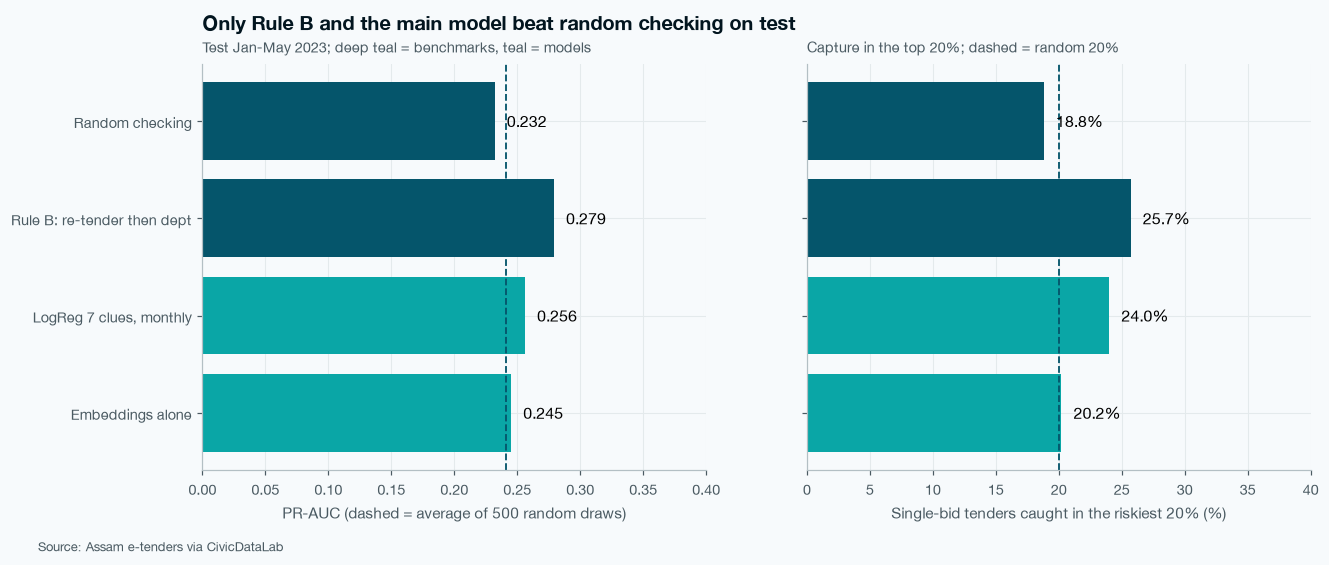

In [77]:
# Chart S7c: PR-AUC (left) and capture top 20% (right) for the 4 methods
show = results_table.iloc[:4]
benchmarks = ["Random checking", "Rule B: re-tender then dept"]
colors = np.where(show["method"].isin(benchmarks), ts.THIRD, ts.MULTI)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

# Left: PR-AUC with the random line
b1 = axes[0].barh(show["method"], show["PR-AUC"], color=colors)
axes[0].bar_label(b1, fmt="%.3f", padding=8)
axes[0].axvline(random_pr, color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[0].set_xlim(0, max(show["PR-AUC"].max() * 1.35, 0.4))
axes[0].invert_yaxis()
axes[0].set_xlabel("PR-AUC (dashed = average of 500 random draws)")
ts.title(axes[0], "Only Rule B and the main model beat random checking on test", subtitle="Test Jan-May 2023; deep teal = benchmarks, teal = models")

# Right: capture in the riskiest 20% with the random 20% line
b2 = axes[1].barh(show["method"], show["capture top 20%"], color=colors)
axes[1].bar_label(b2, fmt="%.1f%%", padding=8)
axes[1].axvline(20, color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[1].set_xlim(0, max(show["capture top 20%"].max() * 1.35, 40))
axes[1].set_xlabel("Single-bid tenders caught in the riskiest 20% (%)")
ts.title(axes[1], " ", subtitle="Capture in the top 20%; dashed = random 20%")

# Source line
ts.source(fig)

In [78]:
ts.save_fig(fig, "../reports/figures/S7c_test_results.png")

The capture curve: if the auditor checks the riskiest X% of tenders, how many of all the single-bid tenders does she find? The dashed straight line is random checking. A line above it means the method does better than random.

In [79]:
# Helper 5: capture for every check share from 0% to 100%
def capture_curve(risk):
    shares = np.arange(0, 101, 5)
    caught = []
    for s in shares:
        if s == 0:
            caught.append(0.0)
        else:
            caught.append(capture(y_te, risk, s / 100))
    return shares, caught

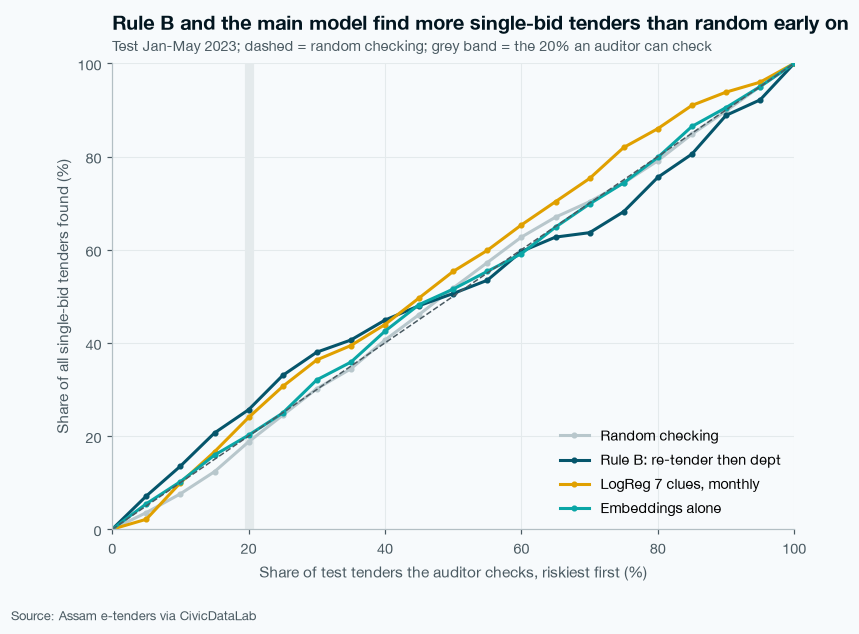

In [80]:
# Chart S7d: capture curve for the 4 methods
line_colors = {}
line_colors["risk_random"] = ts.NEUTRAL
line_colors["risk_ruleb"] = ts.THIRD
line_colors["risk_main"] = ts.SINGLE
line_colors["risk_emb"] = ts.MULTI
fig, ax = plt.subplots(figsize=(8, 5.5))

# One line per method
for col in methods:
    shares, caught = capture_curve(test[col].values)
    ax.plot(shares, caught, color=line_colors[col], label=methods[col], marker="o", markersize=3)

# Straight dashed line = what random checking finds on average, and the 20% check line
ax.plot([0, 100], [0, 100], color=ts.INK2, linestyle="--", linewidth=1)
ax.axvline(20, color=ts.GRID, linewidth=6, zorder=0)

# Axis names, limits, legend
ax.set_xlabel("Share of test tenders the auditor checks, riskiest first (%)")
ax.set_ylabel("Share of all single-bid tenders found (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc="lower right")

# Title, subtitle, source
subtitle = "Test Jan-May 2023; dashed = random checking; grey band = the 20% an auditor can check"
ts.title(ax, "Rule B and the main model find more single-bid tenders than random early on", subtitle=subtitle)
ts.source(fig)

In [81]:
ts.save_fig(fig, "../reports/figures/S7d_capture_curve.png")

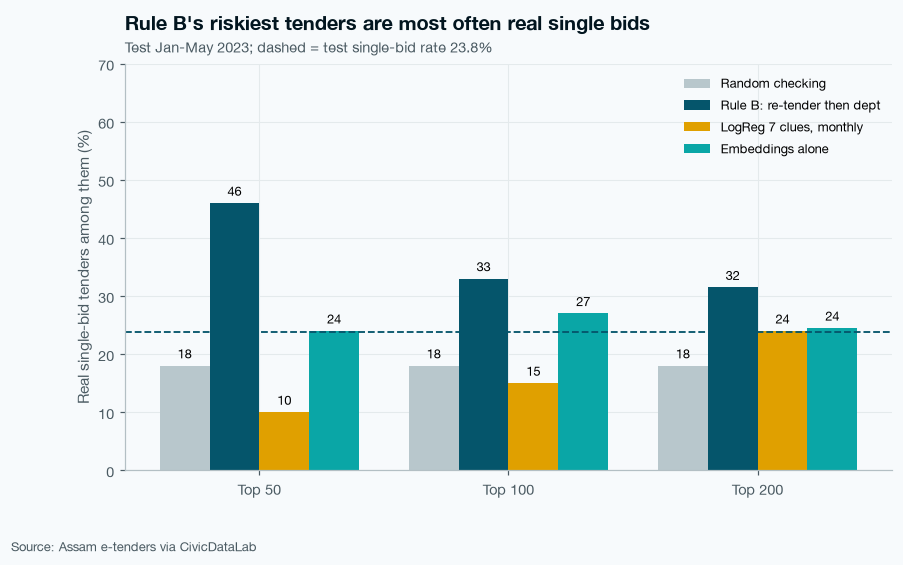

In [82]:
# Chart S7e: precision among the 50, 100 and 200 riskiest tenders
ks = ["precision top 50", "precision top 100", "precision top 200"]
pos = np.arange(len(ks))
fig, ax = plt.subplots(figsize=(9, 4.8))

# 4 bars per group, side by side
b1 = ax.bar(pos - 0.3, show.iloc[0][ks].values.astype(float), width=0.2, color=ts.NEUTRAL, label=show.iloc[0]["method"])
b2 = ax.bar(pos - 0.1, show.iloc[1][ks].values.astype(float), width=0.2, color=ts.THIRD, label=show.iloc[1]["method"])
b3 = ax.bar(pos + 0.1, show.iloc[2][ks].values.astype(float), width=0.2, color=ts.SINGLE, label=show.iloc[2]["method"])
b4 = ax.bar(pos + 0.3, show.iloc[3][ks].values.astype(float), width=0.2, color=ts.MULTI, label=show.iloc[3]["method"])

# % labels on the bars
ax.bar_label(b1, fmt="%.0f", padding=3, fontsize=8.5)
ax.bar_label(b2, fmt="%.0f", padding=3, fontsize=8.5)
ax.bar_label(b3, fmt="%.0f", padding=3, fontsize=8.5)
ax.bar_label(b4, fmt="%.0f", padding=3, fontsize=8.5)

# Dashed line = test single-bid rate (what random picks would give)
ax.axhline(base_rate, color=ts.THIRD, linestyle="--", linewidth=1.2)

# Group names, axis name, room, legend
ax.set_xticks(pos, ["Top 50", "Top 100", "Top 200"])
ax.set_ylabel("Real single-bid tenders among them (%)")
ax.set_ylim(0, 70)
ax.legend(loc="upper right", fontsize=8.5)

# Title, subtitle, source
subtitle = "Test Jan-May 2023; dashed = test single-bid rate " + str(round(base_rate, 1)) + "%"
ts.title(ax, "Rule B's riskiest tenders are most often real single bids", subtitle=subtitle)
ts.source(fig)

In [83]:
ts.save_fig(fig, "../reports/figures/S7e_precision_top_k.png")

## Step 11 · Bootstrap: is the difference real or just luck?

Bootstrap: I make 500 new test sets by picking tenders at random from the test set (the same tender can be picked more than once). Then I score both methods on each of the 500 sets.

If method A beats method B in 95% or more of the 500 sets, I count the win as real. If it is less than 95%, it could just be luck.

I only compare the pairs I wrote down in the locked plan.

In [84]:
# Answers as a plain array
y_arr = y_te.values

In [85]:
# Helper 6: 500 re-draws; PR-AUC of method A minus PR-AUC of method B in each
def bootstrap(col_a, col_b):
    rng_b = np.random.default_rng(42)
    a = test[col_a].values
    b = test[col_b].values
    gaps = []
    for i in range(500):
        pick = rng_b.integers(0, len(test), len(test))
        gaps.append(average_precision_score(y_arr[pick], a[pick]) - average_precision_score(y_arr[pick], b[pick]))
    return np.array(gaps)

In [86]:
# The 3 promised pairs
gaps_main_random = bootstrap("risk_main", "risk_random")
gaps_main_ruleb = bootstrap("risk_main", "risk_ruleb")
gaps_emb_random = bootstrap("risk_emb", "risk_random")

In [87]:
# Helper 7: one table row for one pair
def boot_row(name, gaps):
    row = {}
    row["comparison"] = name
    row["A wins (% of draws)"] = round((gaps > 0).mean() * 100, 1)
    row["gap low (2.5%)"] = round(np.percentile(gaps, 2.5), 3)
    row["gap high (97.5%)"] = round(np.percentile(gaps, 97.5), 3)
    return row

In [88]:
# The bootstrap table
boot_rows = []
boot_rows.append(boot_row("LogReg monthly vs Random", gaps_main_random))
boot_rows.append(boot_row("LogReg monthly vs Rule B", gaps_main_ruleb))
boot_rows.append(boot_row("Embeddings vs Random", gaps_emb_random))
boot_table = pd.DataFrame(boot_rows)
boot_table

,comparison,A wins (% of draws),gap low (2.5%),gap high (97.5%)
0,LogReg monthly vs Random,95.8,-0.003,0.048
1,LogReg monthly vs Rule B,5.2,-0.049,0.004
2,Embeddings vs Random,83.0,-0.014,0.038


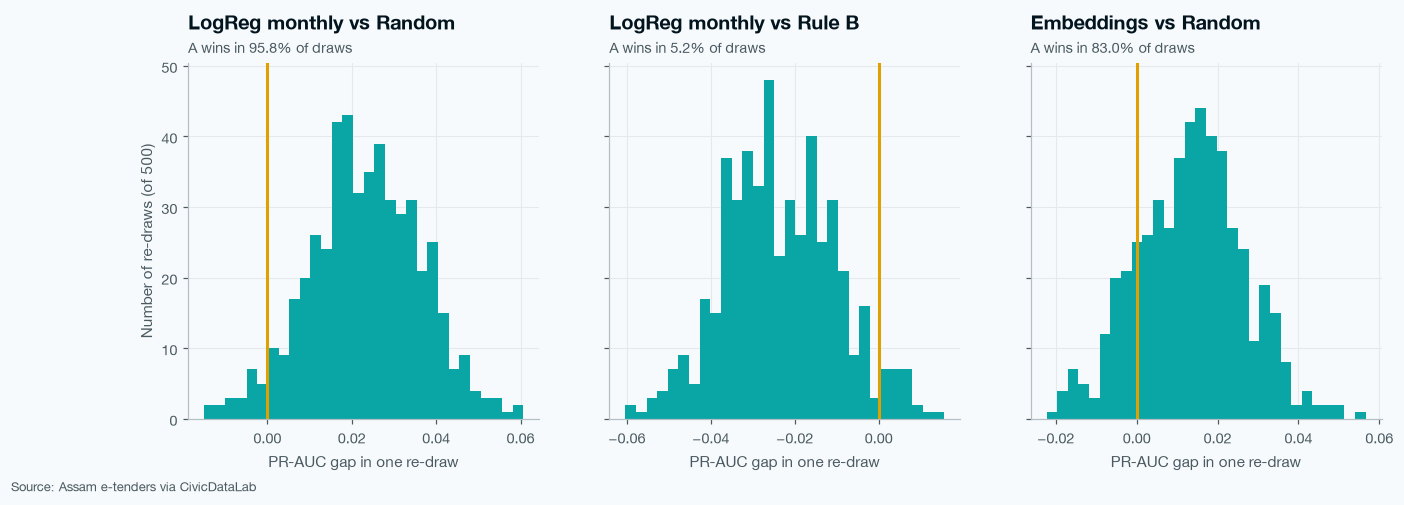

In [89]:
# Chart S7f: the 500 gaps for each pair (right of the amber line = method A is better)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
all_gaps = [gaps_main_random, gaps_main_ruleb, gaps_emb_random]
names = ["LogReg monthly vs Random", "LogReg monthly vs Rule B", "Embeddings vs Random"]

# One small chart per pair
for i in range(3):
    axes[i].hist(all_gaps[i], bins=30, color=ts.BLUES[3])
    axes[i].axvline(0, color=ts.SINGLE, linewidth=2)
    axes[i].set_xlabel("PR-AUC gap in one re-draw")
    win_text = "A wins in " + str(boot_rows[i]["A wins (% of draws)"]) + "% of draws"
    ts.title(axes[i], names[i], subtitle=win_text)

# Y-axis name on the first chart, then the source
axes[0].set_ylabel("Number of re-draws (of 500)")
ts.source(fig)

In [90]:
ts.save_fig(fig, "../reports/figures/S7f_bootstrap.png")

### Insight · Test results (Steps 10 and 11)

- Test has 421 single-bid tenders out of 1,767, which is 23.8%. That is lower than train (36.1%) and validation (27.8%).
- Random checking gives a PR-AUC of about 0.241 on average (500 draws), and it finds about 20% of the single-bid tenders when the auditor checks 20% of tenders.
- Rule B did best: PR-AUC 0.279, and it found 25.7% of the single-bid tenders in its riskiest 20%.
- Our main model (LogReg, 7 clues, monthly) came second: PR-AUC 0.256, ROC-AUC 0.552, and it found 24.0%. Its lift is 1.20, so it is 20% better than random checking.
- Embeddings were almost the same as random on test: PR-AUC 0.245 and 20.2% found.
- In the 500 re-draws the main model beat random checking 95.8% of the time. This is just above the 95% line, so for the first time in this project a model's win over random is real and not luck. But the win is small (the gap goes from -0.003 to 0.048).
- The main model did not beat Rule B (it won only 5.2% of the draws). Embeddings beat random in 83.0% of the draws, which is not enough to call it real.
- One weak point: among the 50 riskiest tenders of the main model only 10% really got one bid. Many of its very top scores are April-May tenders, and April-May had very few single bids. Rule B's top 50 had 46%.

## Step 12 · Month by month (Jan to May 2023)

In [91]:
# Helper 8: single-bid rate and capture top 20% of every method for one month
def month_row(name):
    part = test[test["month_name"] == name]
    row = {}
    row["month"] = name
    row["tenders"] = len(part)
    row["single-bid %"] = round(part["single_bid"].mean() * 100, 1)
    row["Random"] = round(capture(part["single_bid"], part["risk_random"].values, 0.2), 1)
    row["Rule B"] = round(capture(part["single_bid"], part["risk_ruleb"].values, 0.2), 1)
    row["LogReg monthly"] = round(capture(part["single_bid"], part["risk_main"].values, 0.2), 1)
    row["Embeddings"] = round(capture(part["single_bid"], part["risk_emb"].values, 0.2), 1)
    return row

In [92]:
# One row per month
month_rows = []
for name in month_order:
    month_rows.append(month_row(name))
month_table = pd.DataFrame(month_rows)
month_table

,month,tenders,single-bid %,Random,Rule B,LogReg monthly,Embeddings
0,Jan 2023,842,28.5,18.8,27.1,25.0,20.4
1,Feb 2023,485,22.9,19.8,19.8,23.4,17.1
2,Mar 2023,355,18.0,18.8,28.1,28.1,23.4
3,Apr-May 2023,85,7.1,33.3,0.0,16.7,33.3


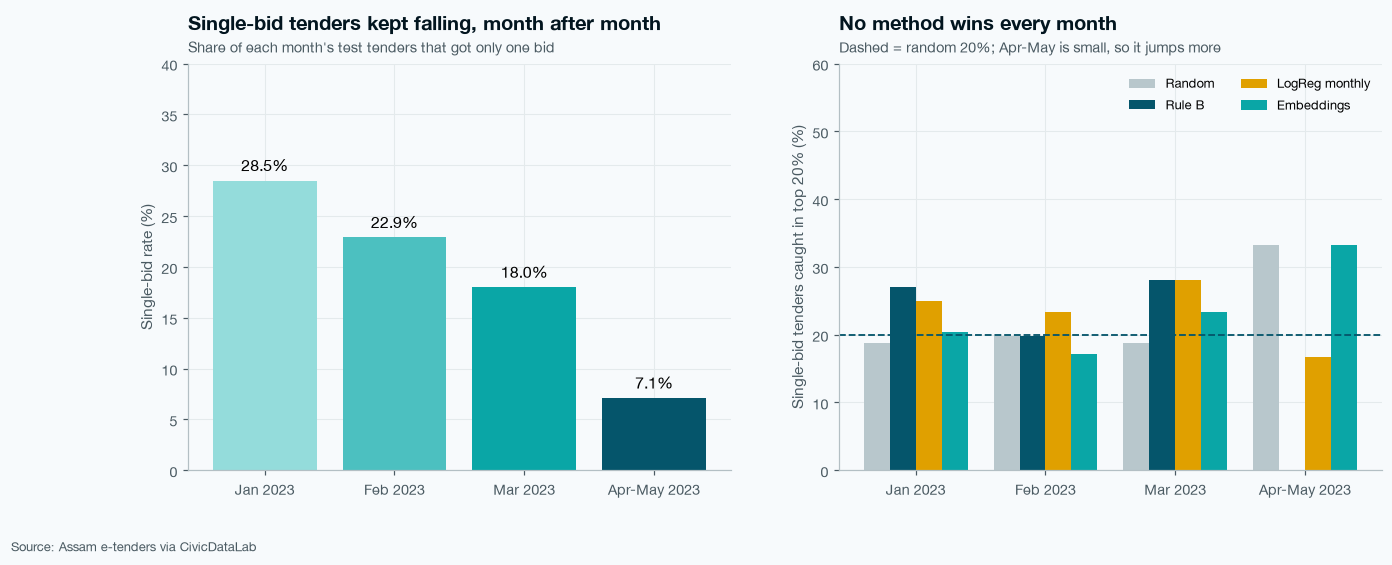

In [93]:
# Chart S7g: left = single-bid rate each month, right = capture top 20% each month
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pos = np.arange(len(month_table))

# Left: single-bid rate per month (teal ramp) with the 30.1% overall line
b0 = axes[0].bar(month_table["month"], month_table["single-bid %"], color=ts.BLUES[1:5])
axes[0].bar_label(b0, fmt="%.1f%%", padding=4)
axes[0].set_ylim(0, 40)
axes[0].set_ylabel("Single-bid rate (%)")
ts.title(axes[0], "Single-bid tenders kept falling, month after month", subtitle="Share of each month's test tenders that got only one bid")

# Right: capture top 20% per method per month
b1 = axes[1].bar(pos - 0.3, month_table["Random"], width=0.2, color=ts.NEUTRAL, label="Random")
b2 = axes[1].bar(pos - 0.1, month_table["Rule B"], width=0.2, color=ts.THIRD, label="Rule B")
b3 = axes[1].bar(pos + 0.1, month_table["LogReg monthly"], width=0.2, color=ts.SINGLE, label="LogReg monthly")
b4 = axes[1].bar(pos + 0.3, month_table["Embeddings"], width=0.2, color=ts.MULTI, label="Embeddings")
axes[1].axhline(20, color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[1].set_xticks(pos, month_table["month"])
axes[1].set_ylim(0, 60)
axes[1].set_ylabel("Single-bid tenders caught in top 20% (%)")
axes[1].legend(loc="upper right", fontsize=8.5, ncol=2)
ts.title(axes[1], "No method wins every month", subtitle="Dashed = random 20%; Apr-May is small, so it jumps more")

# Source line
ts.source(fig)

In [94]:
ts.save_fig(fig, "../reports/figures/S7g_month_by_month.png")

### Insight · Month by month (Step 12)

- The single-bid rate kept falling inside the test months: January 28.5%, February 22.9%, March 18.0% and April-May only 7.1%.
- No method won every month. The main model was above random in January (25.0%), February (23.4%) and March (28.1%), but below it in April-May (16.7%).
- Rule B was strong in January (27.1%) and March (28.1%), only equal to random in February (19.8%), and found nothing in April-May.
- April-May has only 85 tenders and about 6 single-bid tenders, so its numbers jump a lot and I do not trust them much.

## Step 13 · Auditor view: check the riskiest 20%

In [95]:
# How many tenders the auditor checks (20% of test), and all single-bid tenders in test
n_check = int(len(test) * 0.2)
all_single = int(y_te.sum())
print("Checked:", n_check, "| all single-bid tenders in test:", all_single)

Checked: 353 | all single-bid tenders in test: 421


In [96]:
# Helper 9: the riskiest 20% of test tenders for one risk column
def top20(col):
    t = test.sort_values(col, ascending=False, kind="stable")
    return t.head(n_check)

In [97]:
# For each method: single-bid tenders caught and their value in crore (1 crore = 1,00,00,000)
auditor_rows = []
for col in methods:
    top = top20(col)
    caught = top[top["single_bid"] == 1]
    row = {}
    row["method"] = methods[col]
    row["caught"] = len(caught)
    row["caught % of all single-bid"] = round(len(caught) / all_single * 100, 1)
    row["Rs crore caught"] = round(caught["estimated_value"].sum() / 1e7, 1)
    row["caught with no value written"] = int(caught["value_missing"].sum())
    auditor_rows.append(row)
auditor = pd.DataFrame(auditor_rows)
auditor

,method,caught,caught % of all single-bid,Rs crore caught,caught with no value written
0,Random checking,79,18.8,199.5,8
1,Rule B: re-tender then dept,108,25.7,225.4,4
2,"LogReg 7 clues, monthly",101,24.0,170.0,0
3,Embeddings alone,85,20.2,178.3,3


In [98]:
# All single-bid value in test (for scale)
total_crore = test.loc[test["single_bid"] == 1, "estimated_value"].sum() / 1e7
print("Value of all single-bid test tenders: Rs", round(total_crore, 1), "crore")

Value of all single-bid test tenders: Rs 865.7 crore


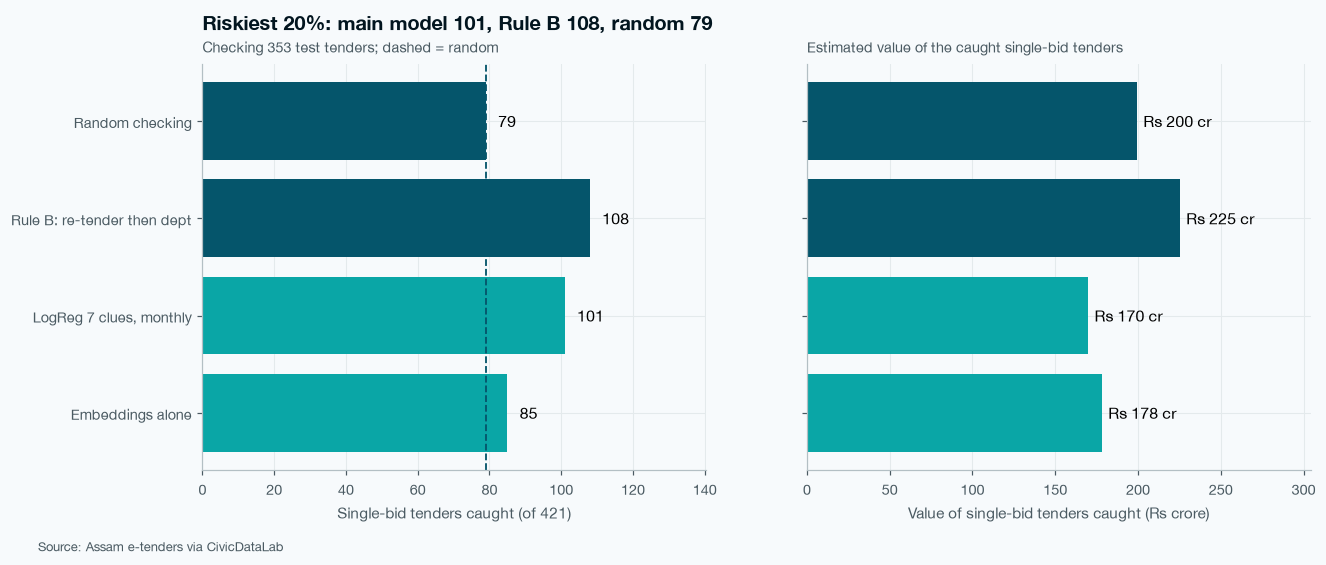

In [99]:
# Chart S7h: caught (left) and rupee value caught (right) for each method
colors = np.where(auditor["method"].isin(benchmarks), ts.THIRD, ts.MULTI)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

# Left: single-bid tenders caught, random as a dashed line
b1 = axes[0].barh(auditor["method"], auditor["caught"], color=colors)
axes[0].bar_label(b1, padding=8)
axes[0].axvline(auditor.loc[0, "caught"], color=ts.THIRD, linestyle="--", linewidth=1.2)
axes[0].set_xlim(0, auditor["caught"].max() * 1.3)
axes[0].invert_yaxis()
axes[0].set_xlabel("Single-bid tenders caught (of " + str(all_single) + ")")
ts.title(axes[0], "Riskiest 20%: main model 101, Rule B 108, random 79", subtitle="Checking " + str(n_check) + " test tenders; dashed = random")

# Right: rupee value of the caught single-bid tenders
b2 = axes[1].barh(auditor["method"], auditor["Rs crore caught"], color=colors)
axes[1].bar_label(b2, fmt="Rs %.0f cr", padding=4)
axes[1].set_xlim(0, auditor["Rs crore caught"].max() * 1.35)
axes[1].set_xlabel("Value of single-bid tenders caught (Rs crore)")
ts.title(axes[1], " ", subtitle="Estimated value of the caught single-bid tenders")

# Source line
ts.source(fig)

In [100]:
ts.save_fig(fig, "../reports/figures/S7h_auditor_view.png")

The confusion table for the main model. "Flagged" means the tender is in the riskiest 20%.

| Box | What it means |
|---|---|
| flagged + one bid | caught (the model was right) |
| flagged + more bids | false alarm (the auditor checks a tender that was fine) |
| not flagged + one bid | missed |
| not flagged + more bids | correctly left alone |

In [101]:
# Flag = 1 for the riskiest 20% of the main model, 0 for the rest
test["flag_main"] = 0
test.loc[top20("risk_main").index, "flag_main"] = 1

In [102]:
# The confusion table (rows = real answer, columns = flag)
cm = confusion_matrix(y_te, test["flag_main"])
cm

array([[1094,  252],
       [ 320,  101]])

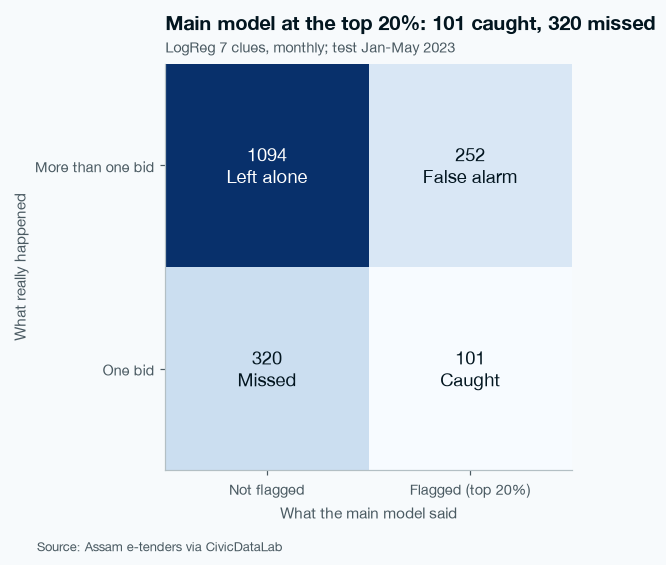

In [103]:
# Chart S7i: the confusion table as coloured boxes
fig, ax = plt.subplots(figsize=(6, 4.8))
ax.imshow(cm, cmap="Blues")
ax.grid(False)

# The number and a short name inside every box
box_names = [["Left alone", "False alarm"], ["Missed", "Caught"]]
for i in range(4):
    r = i // 2
    c = i % 2
    text_color = ts.INK
    if cm[r, c] > cm.max() / 2:
        text_color = "white"
    ax.text(c, r, str(cm[r, c]) + "\n" + box_names[r][c], ha="center", va="center", fontsize=12, color=text_color)

# Labels on both sides
ax.set_xticks([0, 1], ["Not flagged", "Flagged (top 20%)"])
ax.set_yticks([0, 1], ["More than one bid", "One bid"])
ax.set_xlabel("What the main model said")
ax.set_ylabel("What really happened")

# Title, subtitle, source
ts.title(ax, "Main model at the top 20%: 101 caught, 320 missed", subtitle="LogReg 7 clues, monthly; test Jan-May 2023")
ts.source(fig)

In [104]:
ts.save_fig(fig, "../reports/figures/S7i_confusion.png")

### Insight · Auditor view (Step 13)

- If the auditor checks the riskiest 20% (353 tenders), random checking finds 79 of the 421 single-bid tenders.
- The main model finds 101. That is 22 more than random, about 28% more. Rule B finds 108.
- In money: the single-bid tenders found by the main model are worth Rs 170.0 crore, by Rule B Rs 225.4 crore and by random Rs 199.5 crore. All single-bid tenders in test are worth Rs 865.7 crore.
- So the S5 idea that the model finds bigger tenders did not come back on test. The main model finds more tenders, but not more rupees.
- None of the main model's 101 catches had a missing value. The model has learned that tenders with no value written get fewer single bids (see check b in Step 23).
- Confusion table for the main model: 101 caught, 320 missed, 252 false alarms and 1,094 correctly left alone. So 101 of the 353 flagged tenders (28.6%) really got one bid.

## Step 14 · Risk bands: High, Medium, Low

In S5 I found that the scores are not real percentages. So the app will show bands instead:
- High = the riskiest 20% (the auditor checks these first)
- Medium = the next 30%
- Low = the bottom 50%

The bands are only useful if High tenders really get one bid more often than Low tenders. Here I check that.

In [105]:
# Rank of every test tender by the main model (1 = riskiest), then its share from the top
test["rank_main"] = test["risk_main"].rank(ascending=False, method="first")
test["top_share"] = test["rank_main"] / len(test)

In [106]:
# Band: top 20% High, next 30% Medium, the rest Low
test["band"] = np.where(test["top_share"] <= 0.2, "High", np.where(test["top_share"] <= 0.5, "Medium", "Low"))

In [107]:
# Tenders, single-bid tenders and single-bid rate in each band
band_order = ["High", "Medium", "Low"]
band_table = test.groupby("band")["single_bid"].agg(["count", "sum", "mean"]).reindex(band_order)
band_table.columns = ["tenders", "single-bid", "single-bid %"]
band_table["single-bid %"] = (band_table["single-bid %"] * 100).round(1)
band_table

,tenders,single-bid,single-bid %
band,,,
High,353,101.0,28.6
Medium,530,132.0,24.9
Low,884,188.0,21.3


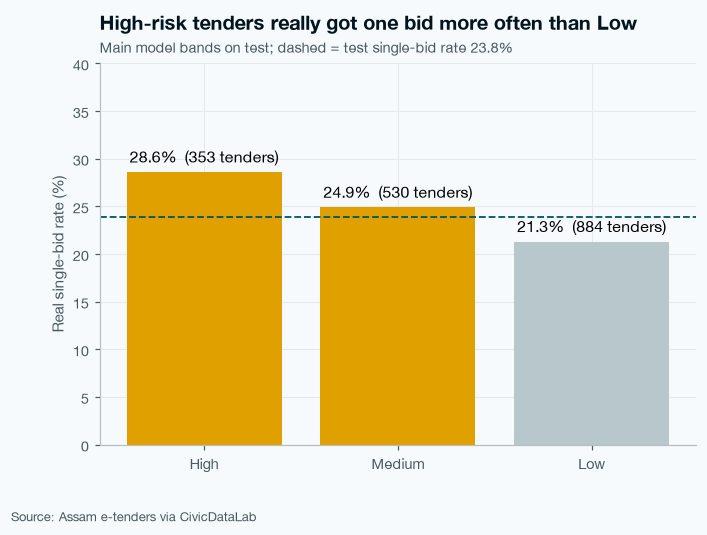

In [108]:
# Chart S7j: real single-bid rate in each band (amber = above the test rate)
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = np.where(band_table["single-bid %"] > base_rate, ts.SINGLE, ts.NEUTRAL)
bars = ax.bar(band_table.index, band_table["single-bid %"], color=colors)

# Labels: rate and number of tenders
labels = []
for b in band_order:
    labels.append(str(band_table.loc[b, "single-bid %"]) + "%  (" + str(band_table.loc[b, "tenders"]) + " tenders)")
ax.bar_label(bars, labels=labels, padding=4)

# Dashed line = test single-bid rate
ax.axhline(base_rate, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.set_ylim(0, max(band_table["single-bid %"].max() * 1.35, 40))
ax.set_ylabel("Real single-bid rate (%)")

# Title, subtitle, source
subtitle = "Main model bands on test; dashed = test single-bid rate " + str(round(base_rate, 1)) + "%"
ts.title(ax, "High-risk tenders really got one bid more often than Low", subtitle=subtitle)
ts.source(fig)

In [109]:
ts.save_fig(fig, "../reports/figures/S7j_risk_bands.png")

Why bands and not percentages? I split the tenders into 5 equal groups by score. For each group I compare the average score with how many really got one bid. If the score was a true percentage, the two bars would be the same height.

In [110]:
# 5 equal groups by score (lowest to highest)
group_names = ["Lowest", "Low", "Middle", "High", "Highest"]
test["score_group"] = pd.qcut(test["risk_main"], 5, labels=group_names)

In [111]:
# Average score and real rate (%) in each group
calib = pd.DataFrame()
calib["average score %"] = test.groupby("score_group", observed=True)["risk_main"].mean() * 100
calib["real single-bid %"] = test.groupby("score_group", observed=True)["single_bid"].mean() * 100
calib.round(1)

,average score %,real single-bid %
score_group,,
Lowest,35.5,16.7
Low,42.5,24.6
Middle,44.2,25.5
High,46.5,23.5
Highest,54.4,28.8


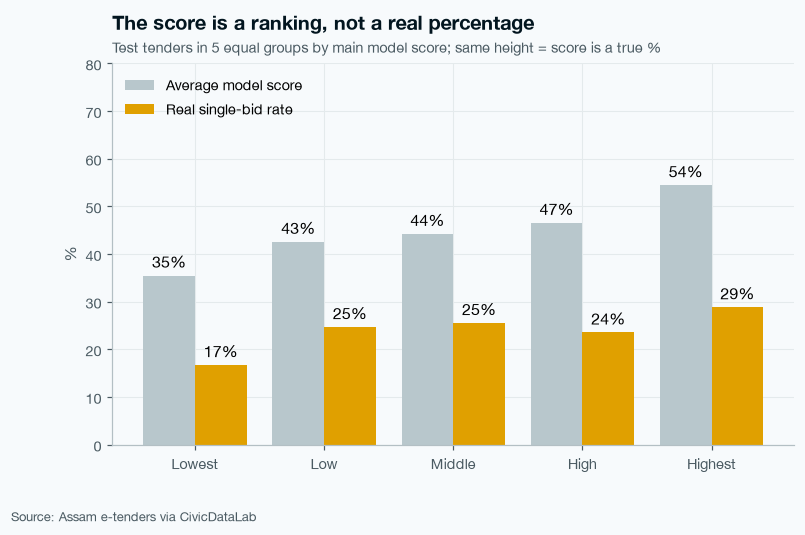

In [112]:
# Chart S7k: average score vs real single-bid rate in each group
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(calib))
b1 = ax.bar(pos - 0.2, calib["average score %"], width=0.4, color=ts.NEUTRAL, label="Average model score")
b2 = ax.bar(pos + 0.2, calib["real single-bid %"], width=0.4, color=ts.SINGLE, label="Real single-bid rate")

# % labels, group names, axis name, room, legend
ax.bar_label(b1, fmt="%.0f%%", padding=3)
ax.bar_label(b2, fmt="%.0f%%", padding=3)
ax.set_xticks(pos, group_names)
ax.set_ylabel("%")
ax.set_ylim(0, 80)
ax.legend(loc="upper left")

# Title, subtitle, source
subtitle = "Test tenders in 5 equal groups by main model score; same height = score is a true %"
ts.title(ax, "The score is a ranking, not a real percentage", subtitle=subtitle)
ts.source(fig)

In [113]:
ts.save_fig(fig, "../reports/figures/S7k_score_vs_real.png")

### Insight · Risk bands (Step 14)

- High band: 353 tenders, 28.6% really got one bid. Medium: 530 tenders, 24.9%. Low: 884 tenders, 21.3%.
- The order is right (High above Medium above Low), and High is above the test rate of 23.8%. So the bands can be used in the app.
- The gap between High and Low is not big (about 7 points). So the bands tell the auditor where to look first. They are not a sure answer.
- The scores are not real percentages. The highest score group had an average score of 54% but only 29% really got one bid. The lowest group had 35% vs 17%. So the app should show High, Medium or Low, not "54% risk". This is what I planned in S5.

## Step 15 · Where does it work best? (department, category, work type)

For each group I check whether the main model still puts single-bid tenders above the others inside that group. ROC-AUC above 0.5 means yes. Below 0.5 means it gets it the wrong way round.

I only keep groups with at least 40 test tenders, and at least 5 single-bid and 5 multi-bid tenders. Smaller groups would give numbers that are mostly luck.

In [114]:
# Helper 10: one row per group with tenders, single-bid rate and the main model's ROC-AUC
def group_table(col):
    rows = []
    for name, part in test.groupby(col):
        singles = int(part["single_bid"].sum())
        if len(part) < 40 or singles < 5 or len(part) - singles < 5:
            continue
        row = {}
        row[col] = name
        row["tenders"] = len(part)
        row["single-bid %"] = round(part["single_bid"].mean() * 100, 1)
        row["ROC-AUC"] = round(roc_auc_score(part["single_bid"], part["risk_main"]), 3)
        row["in High band %"] = round((part["band"] == "High").mean() * 100, 1)
        rows.append(row)
    return pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False)

In [115]:
# By work type (from S6)
work_table = group_table("work_type")
work_table

,work_type,tenders,single-bid %,ROC-AUC,in High band %
2,Other,296,22.0,0.588,17.6
6,Supply of goods,169,13.6,0.581,11.2
3,Power and electrical,60,23.3,0.571,23.3
7,"Water, flood and irrigation",250,30.0,0.542,17.2
4,Roads and bridges,499,29.1,0.530,32.5
5,Schools and hostels,132,17.4,0.521,7.6
0,Buildings and offices,265,25.3,0.484,15.5
1,Health,96,9.4,0.399,12.5


In [116]:
# By category (Works, Goods, Services)
cat_table = group_table("category")
cat_table

,category,tenders,single-bid %,ROC-AUC,in High band %
1,Services,87,26.4,0.644,12.6
0,Goods,224,15.2,0.553,10.3
2,Works,1456,25.0,0.536,21.9


In [117]:
# By department
dept_table = group_table("dept_main")
dept_table

,dept_main,tenders,single-bid %,ROC-AUC,in High band %
0,Assam Power Distribution Company Ltd,43,18.6,0.879,7.0
3,Directorate of Agriculture and Assam Seed Corp...,47,12.8,0.663,4.3
6,Public Works Building and NH Department,221,17.2,0.603,18.6
4,Guwahati Municipal Corporation,149,28.9,0.575,4.7
7,Public Works Roads Department,391,33.8,0.544,47.3
5,Industries and Commerce Department,60,11.7,0.468,28.3
1,Bodoland Territorial Council,289,33.9,0.457,4.5
2,Department of Water Resources,83,25.3,0.429,14.5


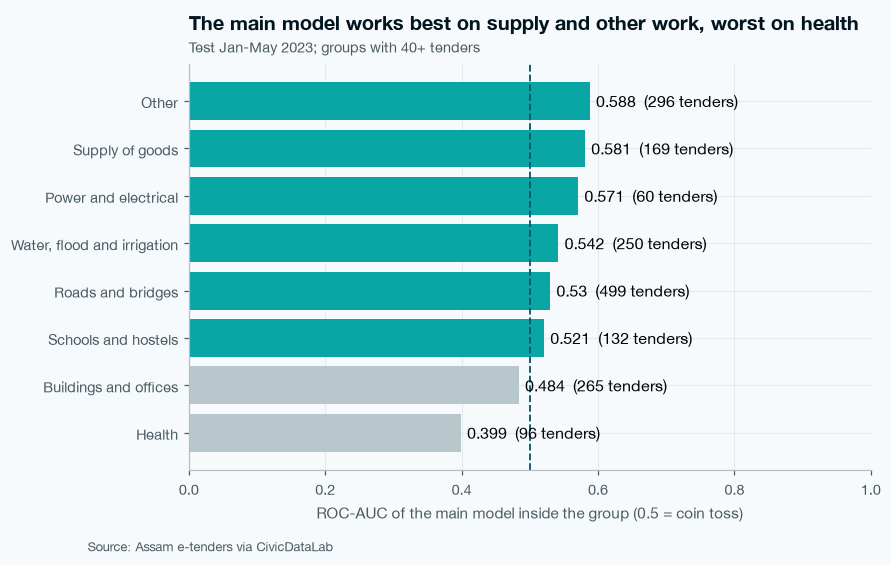

In [118]:
# Chart S7l: ROC-AUC by work type (teal = right way round, grey = wrong way round)
show = work_table.sort_values("ROC-AUC")
colors = np.where(show["ROC-AUC"] > 0.5, ts.MULTI, ts.NEUTRAL)
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.barh(show["work_type"], show["ROC-AUC"], color=colors)

# Labels: ROC and number of tenders
labels = []
for i in range(len(show)):
    labels.append(str(show["ROC-AUC"].iloc[i]) + "  (" + str(show["tenders"].iloc[i]) + " tenders)")
ax.bar_label(bars, labels=labels, padding=4)

# Coin-toss line, room on the right, axis name
ax.axvline(0.5, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.set_xlim(0, 1)
ax.set_xlabel("ROC-AUC of the main model inside the group (0.5 = coin toss)")

# Title, subtitle, source
ts.title(ax, "The main model works best on supply and other work, worst on health", subtitle="Test Jan-May 2023; groups with 40+ tenders")
ts.source(fig)

In [119]:
ts.save_fig(fig, "../reports/figures/S7l_by_work_type.png")

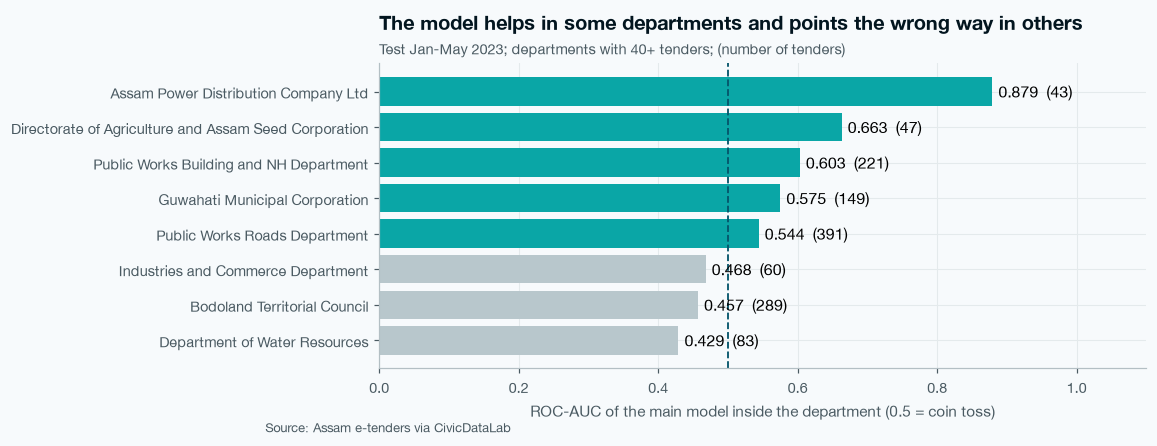

In [120]:
# Chart S7m: ROC-AUC by department (sideways so long names fit)
show = dept_table.sort_values("ROC-AUC")
colors = np.where(show["ROC-AUC"] > 0.5, ts.MULTI, ts.NEUTRAL)
fig, ax = plt.subplots(figsize=(9, max(3.5, len(show) * 0.45)))
bars = ax.barh(show["dept_main"], show["ROC-AUC"], color=colors)

# Labels: ROC and number of tenders
labels = []
for i in range(len(show)):
    labels.append(str(show["ROC-AUC"].iloc[i]) + "  (" + str(show["tenders"].iloc[i]) + ")")
ax.bar_label(bars, labels=labels, padding=4)

# Coin-toss line, room on the right, axis name
ax.axvline(0.5, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.set_xlim(0, 1.1)
ax.set_xlabel("ROC-AUC of the main model inside the department (0.5 = coin toss)")

# Title, subtitle, source
ts.title(ax, "The model helps in some departments and points the wrong way in others", subtitle="Test Jan-May 2023; departments with 40+ tenders; (number of tenders)")
ts.source(fig)

In [121]:
ts.save_fig(fig, "../reports/figures/S7m_by_department.png")

### Insight · Where it works best (Step 15)

- By work type, the model works best on "Other" work (ROC 0.588), supply of goods (0.581) and power and electrical (0.571). It works the wrong way round for buildings (0.484) and health (0.399).
- By category it is above coin toss in all three: Services 0.644, Goods 0.553, Works 0.536.
- By department it is very mixed. Power Distribution (0.879, but only 43 tenders) and Agriculture (0.663) look good, and PWD Roads is a little above coin toss (0.544). Industries (0.468), Bodoland Territorial Council (0.457) and Water Resources (0.429) go the wrong way.
- PWD Roads had 33.8% single-bid and 47.3% of its tenders were in the High band. Bodoland Territorial Council had almost the same rate (33.9%) but only 4.5% of its tenders were High. In S5 I saw BTC's rate go up after Sep 2022, but the department rate clue still comes from the old training months, so the model misses BTC.
- Most groups are small, so these numbers are a guide, not proof.

## Step 16 · Validation vs test: why are they different?

PR-AUC depends on how common single-bid tenders are. Validation had 27.8% single-bid tenders and test has fewer, so I cannot compare the PR-AUC numbers directly. To make it fair, I divide PR-AUC by the single-bid rate. This tells me how many times better than random a method is (1.0 = same as random).

In [122]:
# Validation numbers from S6 (same 4 methods)
s6 = pd.read_csv("../reports/s6_nlp_results.csv").set_index("model")

In [123]:
# The S6 name of each method on validation
val_names = {}
val_names["risk_random"] = "Random"
val_names["risk_ruleb"] = "Rule B: re-tender then dept"
val_names["risk_main"] = "S5 monthly retrain (7 clues) (opened only)"
val_names["risk_emb"] = "Embeddings alone"

In [124]:
# Single-bid rate of each period
train_rate = train["single_bid"].mean() * 100
val_rate = val["single_bid"].mean() * 100
print("Train:", round(train_rate, 1), "% | Validation:", round(val_rate, 1), "% | Test:", round(base_rate, 1), "%")

Train: 36.1 % | Validation: 27.8 % | Test: 23.8 %


In [125]:
# One row per method: PR-AUC and "times better than random" in validation and test
vt_rows = []
for col in methods:
    row = {}
    row["method"] = methods[col]
    row["val PR-AUC"] = s6.loc[val_names[col], "PR-AUC"]
    row["test PR-AUC"] = round(average_precision_score(y_te, test[col]), 3)
    row["val x random"] = round(row["val PR-AUC"] / (val_rate / 100), 2)
    row["test x random"] = round(row["test PR-AUC"] / (base_rate / 100), 2)
    vt_rows.append(row)
vt_table = pd.DataFrame(vt_rows)
vt_table

,method,val PR-AUC,test PR-AUC,val x random,test x random
0,Random checking,0.288,0.232,1.04,0.97
1,Rule B: re-tender then dept,0.268,0.279,0.97,1.17
2,"LogReg 7 clues, monthly",0.248,0.256,0.89,1.07
3,Embeddings alone,0.300,0.245,1.08,1.03


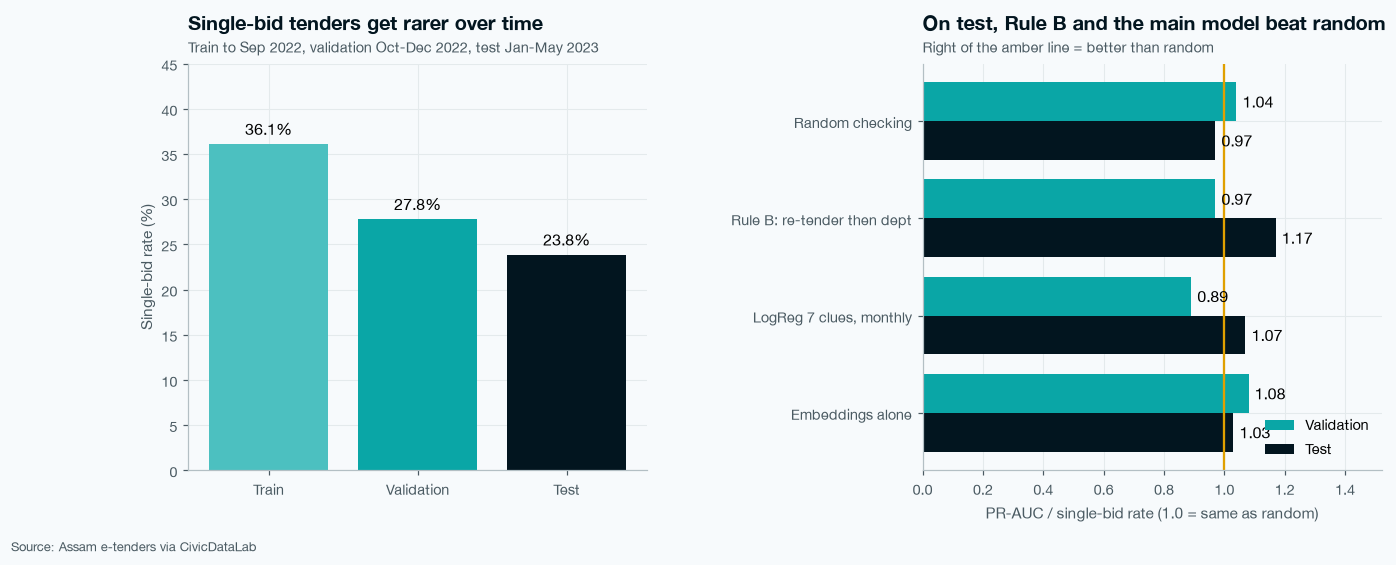

In [126]:
# Chart S7n: left = single-bid rate falls over time, right = times better than random, validation vs test
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Left: train, validation, test single-bid rate (teal ramp)
rates = [train_rate, val_rate, base_rate]
b0 = axes[0].bar(["Train", "Validation", "Test"], rates, color=[ts.BLUES[2], ts.BLUES[3], ts.BLUES[5]])
axes[0].bar_label(b0, fmt="%.1f%%", padding=4)
axes[0].set_ylim(0, 45)
axes[0].set_ylabel("Single-bid rate (%)")
ts.title(axes[0], "Single-bid tenders get rarer over time", subtitle="Train to Sep 2022, validation Oct-Dec 2022, test Jan-May 2023")

# Right: PR-AUC divided by the single-bid rate, validation vs test
pos = np.arange(len(vt_table))
b1 = axes[1].barh(pos - 0.2, vt_table["val x random"], height=0.4, color=ts.BLUES[3], label="Validation")
b2 = axes[1].barh(pos + 0.2, vt_table["test x random"], height=0.4, color=ts.BLUES[5], label="Test")
axes[1].bar_label(b1, fmt="%.2f", padding=4)
axes[1].bar_label(b2, fmt="%.2f", padding=4)
axes[1].axvline(1.0, color=ts.SINGLE, linewidth=1.5)
axes[1].set_yticks(pos, vt_table["method"])
axes[1].invert_yaxis()
axes[1].set_xlim(0, max(vt_table["test x random"].max(), vt_table["val x random"].max()) * 1.3)
axes[1].set_xlabel("PR-AUC / single-bid rate (1.0 = same as random)")
axes[1].legend(loc="lower right")
ts.title(axes[1], "On test, Rule B and the main model beat random", subtitle="Right of the amber line = better than random")

# More space between the two charts so the method names fit
fig.subplots_adjust(wspace=0.6)

# Source line
ts.source(fig)

In [127]:
ts.save_fig(fig, "../reports/figures/S7n_val_vs_test.png")

### Insight · Validation vs test (Step 16)

- Single-bid tenders became rarer: 36.1% in train, 27.8% in validation and 23.8% in test. So the same PR-AUC means different things in each period. To compare fairly I divided PR-AUC by the single-bid rate (1.0 = same as random).
- Main model: 0.89 in validation (below random) but 1.07 in test (above random).
- Rule B: 0.97 in validation and 1.17 in test.
- Embeddings: 1.08 in validation and 1.03 in test. Text was the best method on validation but fell back near random on test. This fits S6: new scheme names keep changing the words, so what the text learned gets old quickly.
- One likely reason the clue model did better on test: some clues were badly upside down in validation but closer to normal in test. For example the department rate clue went from 0.546 in train to 0.412 in validation (wrong way) to 0.503 in test (check e in Step 23). The patterns keep moving, so I cannot promise this will last.

# Part D · Explain the final model (SHAP)

## Step 17 · The final app model: LogReg 7 clues learned on all 6,790 tenders

The test scores above came from the monthly models. That was the fair exam. The app needs one model that has learned from everything I have, so here I train the same model one more time on all 6,790 labelled tenders and save it for S10.

I do not score this model on test, because it has already seen the test answers. I only use it for the app and for the explanations.

In [128]:
# 1. Scaler learned from all labelled tenders
app_scaler = StandardScaler()
app_scaler.fit(lab[base])

StandardScaler()

In [129]:
# 2. and 3. The model, learned from all labelled tenders
app_model = LogisticRegression(class_weight="balanced", max_iter=3000)
app_model.fit(app_scaler.transform(lab[base]), lab["single_bid"])

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [130]:
# The weight of each clue (plus = pushes towards single bid, minus = away)
weights = pd.Series(app_model.coef_[0], index=base).rename(index=nice)
weights.sort_values().round(3)

Value not written                   -0.180
Tender value (log)                  -0.070
Department's past single-bid rate   -0.034
Days to submit bids                  0.021
Lot posted the same day              0.022
Re-tender within 60 days             0.106
Months to financial year end         0.241
dtype: float64

In [131]:
# Save the model, the scaler and the clue list for the app (S10)
os.makedirs("../models", exist_ok=True)
joblib.dump(app_model, "../models/tenderlens_logreg.joblib")
joblib.dump(app_scaler, "../models/tenderlens_scaler.joblib")
pd.DataFrame({"clue": base}).to_csv("../models/tenderlens_clues.csv", index=False)
print("Model saved")

Model saved


In [132]:
# App risk for the test tenders, and the score cut-offs for High and Medium (newest tenders = test)
test["app_risk"] = app_model.predict_proba(app_scaler.transform(test[base]))[:, 1]
high_cut = test["app_risk"].quantile(0.8)
medium_cut = test["app_risk"].quantile(0.5)
print("High from:", round(high_cut, 3), "| Medium from:", round(medium_cut, 3))

High from: 0.503 | Medium from: 0.453


In [133]:
# Save the band cut-offs for the app
cuts = pd.DataFrame({"band": ["High", "Medium"], "score from": [high_cut, medium_cut]})
cuts.to_csv("../models/tenderlens_band_cutoffs.csv", index=False)
cuts

,band,score from
0,High,0.502923
1,Medium,0.452538


## Step 18 · SHAP: which clues matter most overall?

SHAP gives every clue a "push" for every tender:
- a plus push moves the tender towards single bid
- a minus push moves it away
- the average tender's score plus all the pushes gives this tender's score

For Logistic Regression the push is simple: the clue's weight x (this tender's value - the average value).

| Code | What it does |
|---|---|
| `shap.LinearExplainer(model, data)` | the SHAP tool for simple straight-line models; the data tells it what an "average" tender looks like |
| `explainer(X)` | works out the push of every clue for every tender in X |
| `.values` | the pushes as a table (one row per tender, one column per clue) |
| `.base_values` | the starting point (the score of an average tender) |

In [134]:
# All labelled tenders, scaled (this is what "average" means for SHAP)
X_back = pd.DataFrame(app_scaler.transform(lab[base]), columns=base)

In [135]:
# Test tenders, scaled the same way
X_test = pd.DataFrame(app_scaler.transform(test[base]), columns=base, index=test.index)

In [136]:
# The SHAP tool, then the pushes for every test tender
explainer = shap.LinearExplainer(app_model, X_back)
shap_test = explainer(X_test)
shap_test.values.shape

(1767, 7)

In [137]:
# Pushes as a table (one row per test tender, one column per clue)
shap_table = pd.DataFrame(shap_test.values, columns=base, index=test.index)
shap_table.head().round(3)

,dept_rate,log_value,value_missing,bid_window_days,months_to_fy_end,same_day_lot,retender_60d
44,0.046,0.010,-0.444,-0.003,-0.180,-0.006,-0.012
305,-0.036,-0.033,0.060,0.004,-0.105,-0.006,-0.012
306,-0.036,-0.137,0.060,0.004,-0.105,-0.006,-0.012
307,-0.036,-0.050,0.060,0.004,-0.105,-0.006,-0.012
309,-0.036,-0.083,0.060,0.004,-0.105,-0.006,-0.012


In [138]:
# Check: start point + all pushes = the model's raw score (0.0 = exactly the same)
raw_score = app_model.decision_function(X_test.values)
shap_gap = np.abs(shap_table.sum(axis=1).values + shap_test.base_values - raw_score).max()
print("Biggest difference:", round(shap_gap, 8))

Biggest difference: 0.0


In [139]:
# Average size of each clue's push (bigger = matters more), smallest first for the chart
importance = shap_table.abs().mean().sort_values()
importance.rename(index=nice).round(3)

Lot posted the same day              0.007
Days to submit bids                  0.011
Department's past single-bid rate    0.032
Re-tender within 60 days             0.041
Tender value (log)                   0.042
Value not written                    0.115
Months to financial year end         0.232
dtype: float64

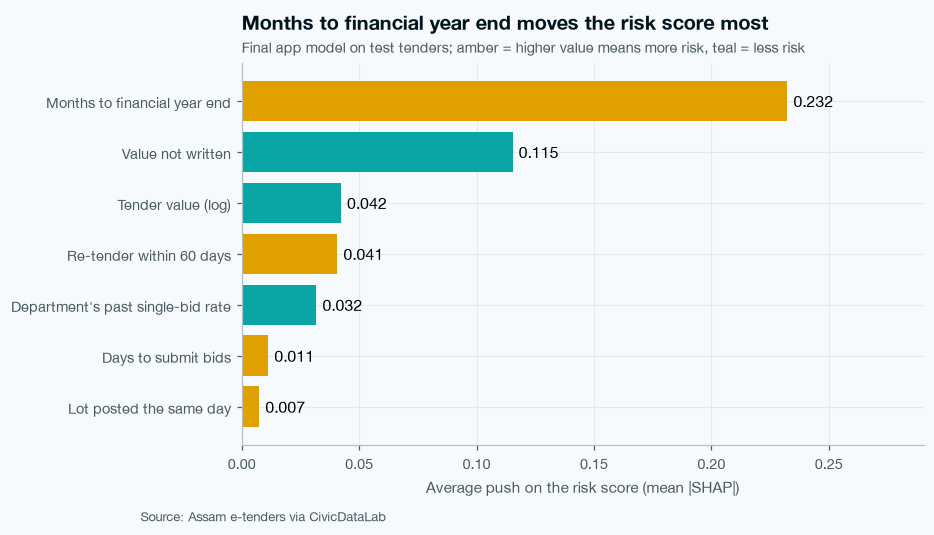

In [140]:
# Chart S7o: how much each clue matters (amber = higher value pushes towards single bid)
colors = []
for clue in importance.index:
    if app_model.coef_[0][base.index(clue)] > 0:
        colors.append(ts.SINGLE)
    else:
        colors.append(ts.MULTI)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(importance.rename(index=nice).index, importance.values, color=colors)

# Labels and axis name
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set_xlim(0, importance.max() * 1.25)
ax.set_xlabel("Average push on the risk score (mean |SHAP|)")

# Title, subtitle, source
subtitle = "Final app model on test tenders; amber = higher value means more risk, teal = less risk"
ts.title(ax, "Months to financial year end moves the risk score most", subtitle=subtitle)
ts.source(fig)

In [141]:
ts.save_fig(fig, "../reports/figures/S7o_shap_importance.png")

The beeswarm chart: each dot is one test tender. A dot on the right means that clue pushed its risk up, and a dot on the left means it pushed it down. The colour shows the clue's value for that tender (red = high, blue = low).

In [142]:
# Easy clue names for the beeswarm
nice_list = []
for clue in base:
    nice_list.append(nice[clue])
shap_test.feature_names = nice_list

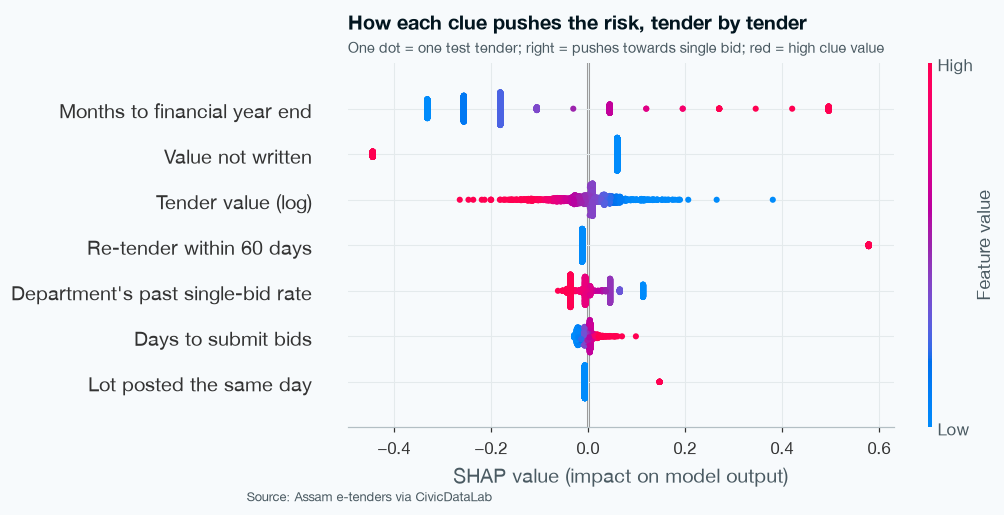

In [143]:
# Chart S7p: SHAP beeswarm (a new empty figure first, then the shap library draws on it)
fig = plt.figure(figsize=(9, 5))
shap.plots.beeswarm(shap_test, show=False)
ax = plt.gca()
subtitle = "One dot = one test tender; right = pushes towards single bid; red = high clue value"
ts.title(ax, "How each clue pushes the risk, tender by tender", subtitle=subtitle)
ts.source(fig)

In [144]:
ts.save_fig(fig, "../reports/figures/S7p_shap_beeswarm.png")

## Step 19 · SHAP dependence for the top 2 clues

For the two clues that matter most, I check how the push changes as the clue value goes up.

In [145]:
# The 2 clues with the biggest average push
top2 = list(importance.sort_values(ascending=False).index[:2])
top2

['months_to_fy_end', 'value_missing']

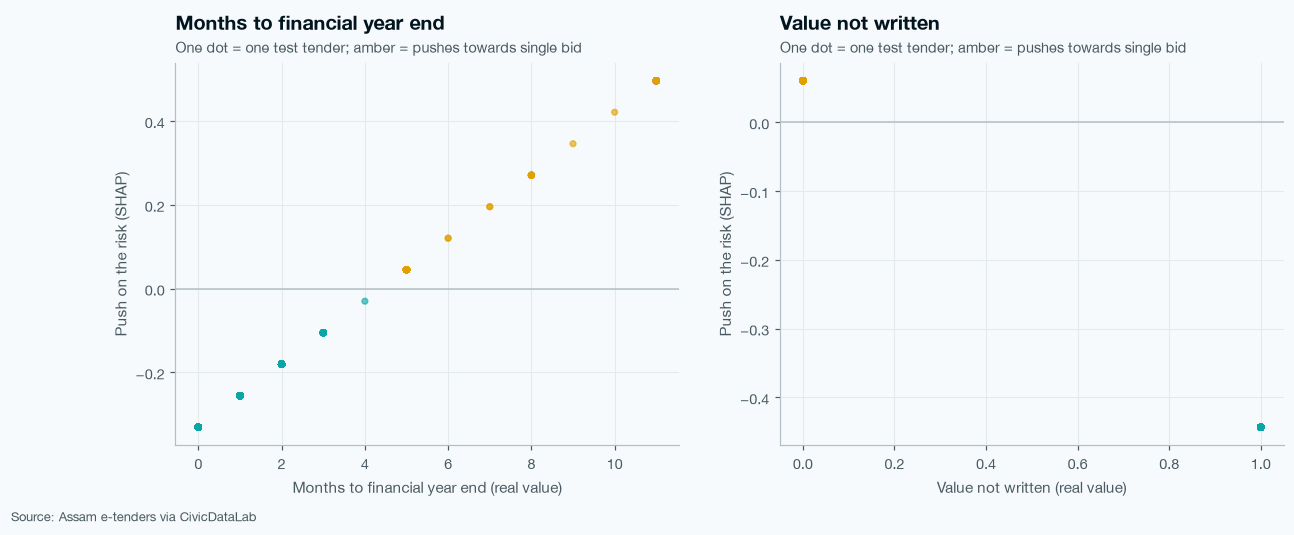

In [146]:
# Chart S7q: clue value (x) vs its push (y) for the top 2 clues
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i in range(2):
    clue = top2[i]
    colors = np.where(shap_table[clue] > 0, ts.SINGLE, ts.MULTI)
    axes[i].scatter(test[clue], shap_table[clue], c=colors, s=14, alpha=0.6)
    axes[i].axhline(0, color=ts.AXIS, linewidth=1)
    axes[i].set_xlabel(nice[clue] + " (real value)")
    axes[i].set_ylabel("Push on the risk (SHAP)")
    ts.title(axes[i], nice[clue], subtitle="One dot = one test tender; amber = pushes towards single bid")
ts.source(fig)

In [147]:
ts.save_fig(fig, "../reports/figures/S7q_shap_dependence.png")

## Step 20 · Five example tenders: why did each get its risk?

Here I pick five real test tenders. For the first four, the monthly model and the app model both put the tender in the same band, so the story is clear:
1. High risk, and it really got one bid (caught)
2. High risk, but it got more bids (false alarm)
3. Low risk, but it got one bid (missed)
4. Low risk, and it got more bids (correctly left alone)
5. The biggest tender in test by rupee value

I will also use these five tenders for the GenAI review brief in S10.

In [148]:
# App band for every test tender (same cut points as the bands: top 20% and top 50%)
test["app_band"] = np.where(test["app_risk"] >= high_cut, "High", np.where(test["app_risk"] >= medium_cut, "Medium", "Low"))

In [149]:
# Both models agree on High, or both agree on Low
both_high = (test["band"] == "High") & (test["app_band"] == "High")
both_low = (test["band"] == "Low") & (test["app_band"] == "Low")
print("Both High:", both_high.sum(), "| Both Low:", both_low.sum())

Both High: 308 | Both Low: 826


In [150]:
# 1. Catch: both High, one bid -> the riskiest one
pick_hit = test[both_high & (test["single_bid"] == 1)]["app_risk"].idxmax()

In [151]:
# 2. False alarm: both High, more bids -> the riskiest one
pick_alarm = test[both_high & (test["single_bid"] == 0)]["app_risk"].idxmax()

In [152]:
# 3. Miss: both Low, one bid -> the lowest risk one
pick_miss = test[both_low & (test["single_bid"] == 1)]["app_risk"].idxmin()

In [153]:
# 4. Left alone: both Low, more bids -> the lowest risk one
pick_alone = test[both_low & (test["single_bid"] == 0)]["app_risk"].idxmin()

In [154]:
# 5. The biggest rupee tender in test
pick_big = test["estimated_value"].idxmax()

In [155]:
# The five tenders in one small table
picks = [pick_hit, pick_alarm, pick_miss, pick_alone, pick_big]
pick_names = ["1 Catch", "2 False alarm", "3 Miss", "4 Left alone", "5 Biggest value"]
examples = test.loc[picks, ["tender_id", "dept_main", "title", "estimated_value", "band", "app_band", "single_bid"]].copy()
examples.insert(0, "example", pick_names)
examples

,example,tender_id,dept_main,title,estimated_value,band,app_band,single_bid
6751,1 Catch,2023_BoTC_30370_1,Bodoland Territorial Council,"Arrangement of Temporary Pandal, Dias, Barrica...",2.560783e+06,High,High,1.0
6754,2 False alarm,2023_APDCL_30348_1,Assam Power Distribution Company Ltd,"Design, Supply, Installation, Testing and comm...",2.279474e+07,High,High,0.0
6549,3 Miss,2023_DCA_29934_1,Department of Cultural Affairs,TO SELECT A SUITABLE AGENCY TO PROVIDE VIDEO P...,NaN,Low,Low,1.0
6453,4 Left alone,2023_DAASC_29777_1,Directorate of Agriculture and Assam Seed Corp...,Empanelment of manufacturers/systems integrato...,NaN,Low,Low,0.0
5835,5 Biggest value,2023_PWD_29045_1,Public Works Roads Department,SOPD_G_22_23_16 Upgradation/ widening of exist...,2.983200e+09,Low,Low,0.0


In [156]:
# Helper 11: a "why" chart for one tender (amber = pushes towards single bid, teal = away)
def why_chart(idx, heading):
    pushes = shap_table.loc[idx].sort_values()
    names = []
    for clue in pushes.index:
        value = test.loc[idx, clue]
        lakh = test.loc[idx, "estimated_value"] / 1e5
        if clue == "log_value" and test.loc[idx, "value_missing"] == 1:
            names.append("Tender value = not written")
        elif clue == "log_value" and lakh >= 100:
            names.append("Tender value = Rs " + str(round(lakh / 100, 1)) + " crore")
        elif clue == "log_value":
            names.append("Tender value = Rs " + str(round(lakh, 1)) + " lakh")
        else:
            names.append(nice[clue] + " = " + str(round(value, 2)))
    colors = np.where(pushes > 0, ts.SINGLE, ts.MULTI)
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    ax.barh(names, pushes.values, color=colors)
    ax.axvline(0, color=ts.AXIS, linewidth=1)
    ax.set_xlabel("Push on the risk (plus = towards single bid)")
    real = "more than one bid"
    if test.loc[idx, "single_bid"] == 1:
        real = "one bid"
    subtitle = str(test.loc[idx, "dept_main"])[:45] + " | band: " + test.loc[idx, "app_band"] + " | really got " + real
    ts.title(ax, heading, subtitle=subtitle)
    ts.source(fig)
    return fig

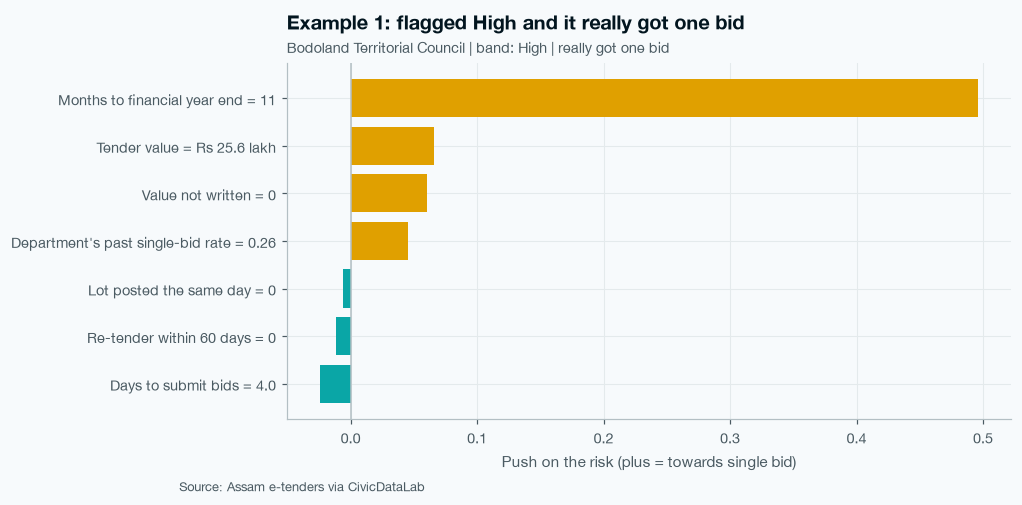

In [157]:
# Example 1: a catch
fig = why_chart(pick_hit, "Example 1: flagged High and it really got one bid")
ts.save_fig(fig, "../reports/figures/S7r1_why_catch.png")

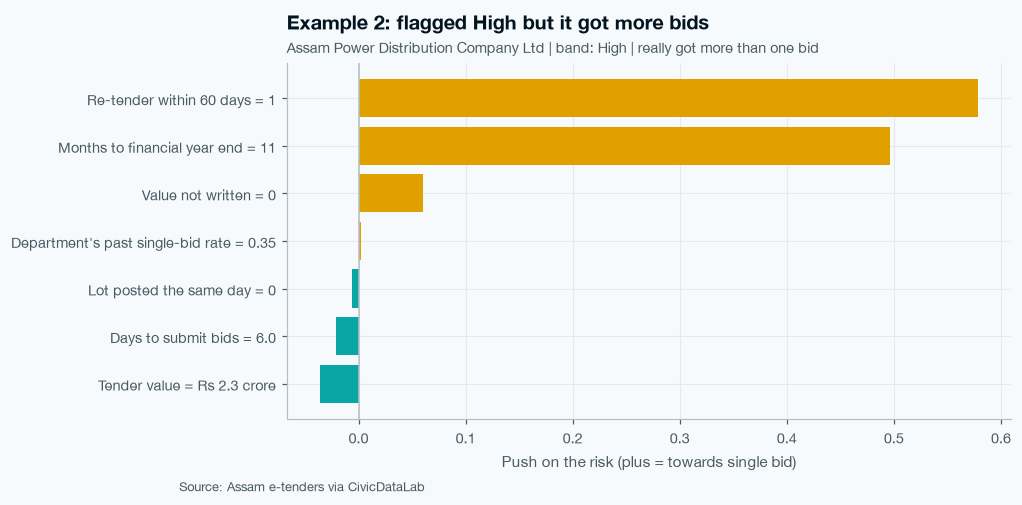

In [158]:
# Example 2: a false alarm
fig = why_chart(pick_alarm, "Example 2: flagged High but it got more bids")
ts.save_fig(fig, "../reports/figures/S7r2_why_false_alarm.png")

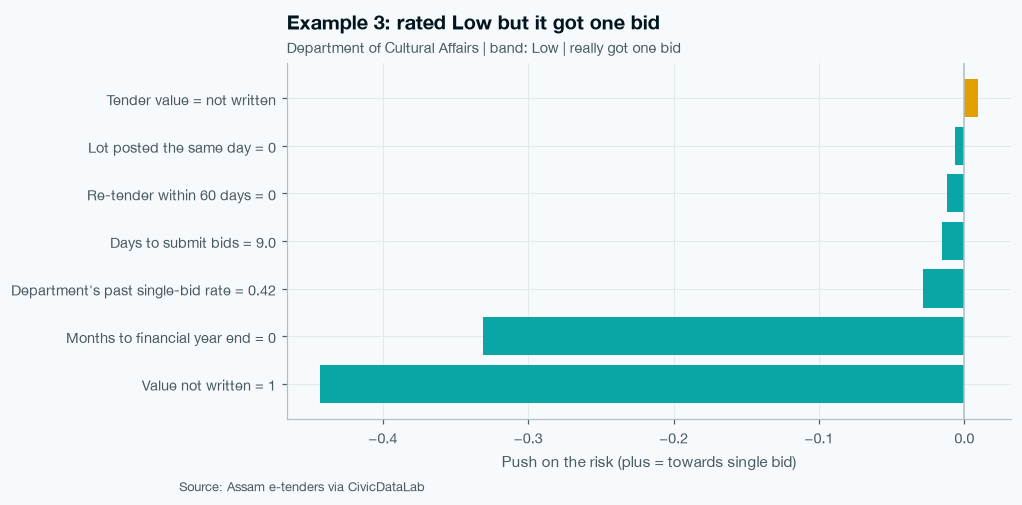

In [159]:
# Example 3: a miss
fig = why_chart(pick_miss, "Example 3: rated Low but it got one bid")
ts.save_fig(fig, "../reports/figures/S7r3_why_miss.png")

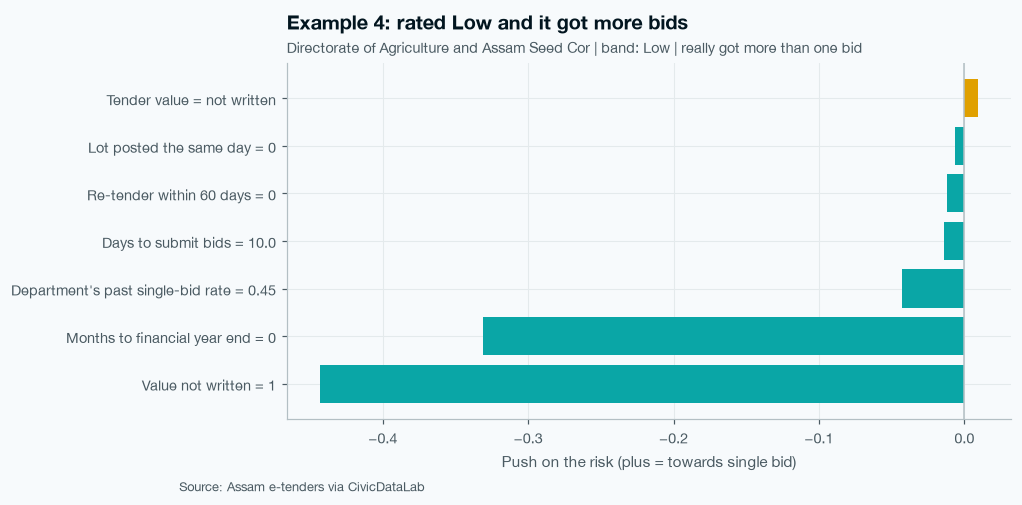

In [160]:
# Example 4: correctly left alone
fig = why_chart(pick_alone, "Example 4: rated Low and it got more bids")
ts.save_fig(fig, "../reports/figures/S7r4_why_left_alone.png")

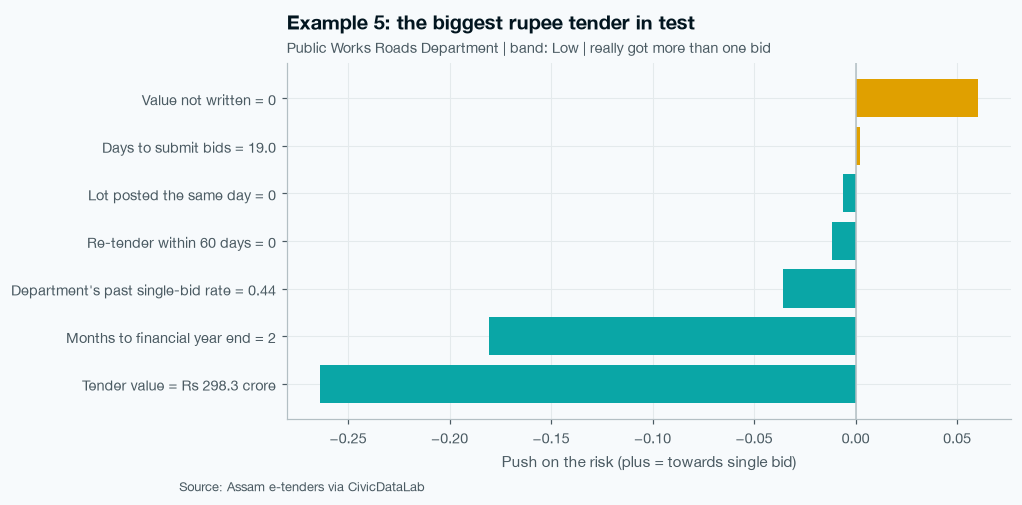

In [161]:
# Example 5: the biggest rupee tender
fig = why_chart(pick_big, "Example 5: the biggest rupee tender in test")
ts.save_fig(fig, "../reports/figures/S7r5_why_biggest.png")

In [162]:
# The titles of the five tenders (so we know what work they are)
for i in range(5):
    print(pick_names[i], "|", test.loc[picks[i], "title"][:110])

1 Catch | Arrangement of Temporary Pandal, Dias, Barricading, Branding in connection with Inauguration Ceremony of Medic
2 False alarm | Design, Supply, Installation, Testing and commissioning including 5 years Operation, Comprehensive Warranty an
3 Miss | TO SELECT A SUITABLE AGENCY TO PROVIDE VIDEO PRODUCTION/EVENT MANAGEMENT / STADIUM AUDIO MASTER AUDIO RECORDIN
4 Left alone | Empanelment of manufacturers/systems integrators for supply, Installation and Commissioning of SPV Water Pumpi
5 Biggest value | SOPD_G_22_23_16 Upgradation/ widening of existing 2 lane Road to 4 lane Road connecting LGB International Airp


### Insight · SHAP and five example tenders (Steps 17 to 20)

- The final app model learned from all 6,790 tenders. It is saved in the models folder with its scaler, the clue list and the band cut-offs (High from a score of 0.503, Medium from 0.453).
- SHAP check: the start point plus all the pushes gives exactly the model's score (difference 0.0), so the explanations add up.
- The clue that moves the score most is months to financial year end (average push 0.232). Tenders published early in the financial year (April, 11 months left) are pushed up, and tenders in March (0 months left) are pushed down.
- Second is value not written (0.115). Tenders with no value written are pushed down, because they really do get fewer single bids (13.4% vs 25.6% on test).
- The other clues push only a little: tender value 0.042, re-tender 0.041, department rate 0.032, days to submit bids 0.011, same-day lot 0.007.
- Important: months to financial year end is the same for every tender in one month. So it changes which month looks risky, but not which tender is riskiest inside a month. Inside a month the work is done by the value, re-tender and department clues.
- The five examples show this. Example 1 (a Bodoland pandal arrangement, really got one bid) and Example 2 (a power company supply job, got more bids) were both pushed up mostly because they were published in April. Example 2 was also a quick re-tender. Examples 3 and 4 were pushed down because no value was written and they were published in March. Example 5, the biggest tender (a Rs 298 crore 4-lane road by PWD Roads), was pushed down by its very big value, and it did get more than one bid.
- These five tenders and their pushes are saved for the GenAI review brief in S10.

# Part E · Model card, saving files and extra checks

## Step 21 · Model card

A model card is a one-page summary of a model, like the label on a medicine box. It says what the model is for, what data it learned from, how well it works, and when it should not be used. All the numbers below come from this run.

In [163]:
# Main model numbers from the results table
main = results_table[results_table["method"] == "LogReg 7 clues, monthly"].iloc[0]
rand = results_table[results_table["method"] == "Random (average of 500 draws)"].iloc[0]
main_caught = auditor.loc[auditor["method"] == "LogReg 7 clues, monthly", "caught"].iloc[0]
rand_caught = auditor.loc[auditor["method"] == "Random checking", "caught"].iloc[0]

In [164]:
# The model card, line by line
card = []
card.append("# TenderLens model card")
card.append("")
card.append("## What it does")
card.append("- Gives each new Assam government tender a single-bid risk band (High / Medium / Low) on the day it is published.")
card.append("- Screening support only: it tells an auditor where to look first. It is NOT fraud detection.")
card.append("")
card.append("## Model")
card.append("- Logistic Regression (class weights balanced) on 7 publish-day clues: " + ", ".join(nice_list) + ".")
card.append("- Retrained at the start of every month, learning only from tenders whose bids were already opened (opened only rule).")
card.append("- App file: models/tenderlens_logreg.joblib, learned on all 6,790 labelled tenders.")
card.append("")
card.append("## Data")
card.append("- Assam e-tenders portal via CivicDataLab, Apr 2016 - May 2023; 39,411 tenders, 6,790 with a verified bidder list.")
card.append("- Target: 1 = exactly one bid, 0 = more than one bid.")
card.append("- Time split: train to Sep 2022 (2,753), validation Oct-Dec 2022 (2,270), test Jan-May 2023 (1,767).")
card.append("")
card.append("## Results on test (scored once)")
card.append("- Test single-bid rate: " + str(round(base_rate, 1)) + "%.")
card.append("- PR-AUC " + str(main["PR-AUC"]) + " vs random " + str(rand["PR-AUC"]) + "; ROC-AUC " + str(main["ROC-AUC"]) + ".")
card.append("- Checking the riskiest 20% (" + str(n_check) + " tenders) finds " + str(main_caught) + " single-bid tenders vs " + str(rand_caught) + " by random checking.")
card.append("- Bootstrap: beats random in " + str(boot_rows[0]["A wins (% of draws)"]) + "% of 500 re-draws, beats Rule B in " + str(boot_rows[1]["A wins (% of draws)"]) + "%.")
card.append("- Real single-bid rate by band: High " + str(band_table.loc["High", "single-bid %"]) + "%, Medium " + str(band_table.loc["Medium", "single-bid %"]) + "%, Low " + str(band_table.loc["Low", "single-bid %"]) + "%.")
card.append("")
card.append("## Limits")
card.append("- Drift: single-bid tenders fell from 36.1% (train) to 27.8% (validation) to " + str(round(base_rate, 1)) + "% (test), and many clues changed direction after Sep 2022 (new schemes, December road-work wave).")
card.append("- Label timing: a tender's answer is known only after its bid opening date (about 19 days after publishing).")
card.append("- Scores are a ranking, not real percentages, so the app shows bands.")
card.append("- Publish-day clues are weak; the portal cuts descriptions at 250 letters.")
card.append("")
card.append("## Intended use")
card.append("- Monthly retraining on tenders whose bids are already opened; show bands, with SHAP reasons and a plain-English brief.")
card.append("- A human auditor always decides. Do not use it to blame a department or a supplier.")

In [165]:
# Show the card and save it as a markdown file
card_text = "\n".join(card)
open("../reports/s7_model_card.md", "w").write(card_text)
display(Markdown(card_text))

# TenderLens model card

## What it does
- Gives each new Assam government tender a single-bid risk band (High / Medium / Low) on the day it is published.
- Screening support only: it tells an auditor where to look first. It is NOT fraud detection.

## Model
- Logistic Regression (class weights balanced) on 7 publish-day clues: Department's past single-bid rate, Tender value (log), Value not written, Days to submit bids, Months to financial year end, Lot posted the same day, Re-tender within 60 days.
- Retrained at the start of every month, learning only from tenders whose bids were already opened (opened only rule).
- App file: models/tenderlens_logreg.joblib, learned on all 6,790 labelled tenders.

## Data
- Assam e-tenders portal via CivicDataLab, Apr 2016 - May 2023; 39,411 tenders, 6,790 with a verified bidder list.
- Target: 1 = exactly one bid, 0 = more than one bid.
- Time split: train to Sep 2022 (2,753), validation Oct-Dec 2022 (2,270), test Jan-May 2023 (1,767).

## Results on test (scored once)
- Test single-bid rate: 23.8%.
- PR-AUC 0.256 vs random 0.241; ROC-AUC 0.552.
- Checking the riskiest 20% (353 tenders) finds 101 single-bid tenders vs 79 by random checking.
- Bootstrap: beats random in 95.8% of 500 re-draws, beats Rule B in 5.2%.
- Real single-bid rate by band: High 28.6%, Medium 24.9%, Low 21.3%.

## Limits
- Drift: single-bid tenders fell from 36.1% (train) to 27.8% (validation) to 23.8% (test), and many clues changed direction after Sep 2022 (new schemes, December road-work wave).
- Label timing: a tender's answer is known only after its bid opening date (about 19 days after publishing).
- Scores are a ranking, not real percentages, so the app shows bands.
- Publish-day clues are weak; the portal cuts descriptions at 250 letters.

## Intended use
- Monthly retraining on tenders whose bids are already opened; show bands, with SHAP reasons and a plain-English brief.
- A human auditor always decides. Do not use it to blame a department or a supplier.

## Step 22 · Save everything

In [166]:
# 1. Test tenders with every method's risk, the band and the app risk
keep = ["tender_id", "published_date", "month_name", "dept_main", "category", "work_type", "title", "estimated_value", "single_bid"]
keep = keep + ["risk_random", "risk_ruleb", "risk_main", "risk_emb", "band", "app_risk", "app_band"]
test[keep].to_csv("../reports/s7_test_predictions.csv", index=False)

In [167]:
# 2. Results, bootstrap, month, auditor, band and validation-vs-test tables
results_table.to_csv("../reports/s7_test_results.csv", index=False)
boot_table.to_csv("../reports/s7_bootstrap.csv", index=False)
month_table.to_csv("../reports/s7_month_table.csv", index=False)
auditor.to_csv("../reports/s7_auditor_view.csv", index=False)
band_table.to_csv("../reports/s7_risk_bands.csv")
vt_table.to_csv("../reports/s7_val_vs_test.csv", index=False)

In [168]:
# 3. Where it works best (work type, category, department)
work_table.to_csv("../reports/s7_by_work_type.csv", index=False)
cat_table.to_csv("../reports/s7_by_category.csv", index=False)
dept_table.to_csv("../reports/s7_by_department.csv", index=False)

In [169]:
# 4. SHAP pushes for every test tender, and the five examples (for the GenAI brief in S10)
shap_out = shap_table.copy()
shap_out.insert(0, "tender_id", test["tender_id"])
shap_out.to_csv("../reports/s7_shap_test.csv", index=False)
examples.join(shap_table).to_csv("../reports/s7_example_tenders.csv", index=False)
print("All saved")

All saved


## Step 23 · Did I miss anything? (extra checks only, no new methods)

These are only checks, not new methods. They help me understand the result better. None of them replaces the locked results above.

### (a) Repeated lots counted once

In [170]:
# Keep only the first tender of each department + cleaned title in test
once = test.drop_duplicates(subset=["dept_main", "title_key"], keep="first")
print("Test tenders:", len(test), "| counted once:", len(once))

Test tenders: 1767 | counted once: 1717


In [171]:
# Main model and random on the counted-once tenders
once_rows = []
once_rows.append(score_row("Random checking (once)", once["single_bid"], once["risk_random"].values))
once_rows.append(score_row("LogReg 7 clues, monthly (once)", once["single_bid"], once["risk_main"].values))
pd.DataFrame(once_rows)

,method,PR-AUC,ROC-AUC,capture top 10%,capture top 20%,capture top 30%,lift top 20%,precision top 50,precision top 100,precision top 200
0,Random checking (once),0.230,0.495,7.6,18.6,30.1,0.93,18.0,19.0,18.5
1,"LogReg 7 clues, monthly (once)",0.254,0.549,9.5,23.7,35.2,1.19,10.0,16.0,24.0


### (b) Value not written: still fewer single bids?

In [172]:
# Single-bid rate (%) with and without a written value, in each split
vm = lab.groupby(["split", "value_missing"])["single_bid"].mean().unstack() * 100
vm = vm.reindex(["train", "val", "test"])
vm.columns = ["value written %", "value not written %"]
vm.round(1)

,value written %,value not written %
split,,
train,38.1,28.7
val,28.5,19.6
test,25.6,13.4


### (c) Quick re-tenders (Rule B's top group) on test

In [173]:
# Single-bid rate (%) of quick re-tenders vs the rest, in each split
rt = lab.groupby(["split", "retender_60d"])["single_bid"].mean().unstack() * 100
rt = rt.reindex(["train", "val", "test"])
rt.columns = ["not a re-tender %", "quick re-tender %"]
rt.round(1)

,not a re-tender %,quick re-tender %
split,,
train,36.1,35.6
val,27.1,58.3
test,23.3,34.4


### (d) Does monthly retraining help? (same model, learned once on 1 Jan)

In [174]:
# Same 7-clue model learned once from tenders opened before 1 Jan 2023 (check only)
learn_once = tv[tv["bid_opening_date"] < "2023-01-01"]
once_risk = lr_risk(learn_once, test, base)
pd.DataFrame([score_row("LogReg 7 clues, learned once (check)", y_te, once_risk), score_row("LogReg 7 clues, monthly", y_te, test["risk_main"].values)])

,method,PR-AUC,ROC-AUC,capture top 10%,capture top 20%,capture top 30%,lift top 20%,precision top 50,precision top 100,precision top 200
0,"LogReg 7 clues, learned once (check)",0.258,0.552,10.5,24.2,35.9,1.21,16.0,19.0,24.0
1,"LogReg 7 clues, monthly",0.256,0.552,10.0,24.0,36.3,1.20,10.0,15.0,24.0


### (e) Does each clue still point the same way? (ROC-AUC of each clue alone)

In [175]:
# ROC-AUC of each clue alone in train, validation and test (above 0.5 = higher value, more single bids)
te_part = lab[lab["split"] == "test"]
flip_rows = []
for clue in base:
    row = {}
    row["clue"] = nice[clue]
    row["train"] = round(roc_auc_score(train["single_bid"], train[clue]), 3)
    row["validation"] = round(roc_auc_score(val["single_bid"], val[clue]), 3)
    row["test"] = round(roc_auc_score(te_part["single_bid"], te_part[clue]), 3)
    flip_rows.append(row)
flip_table = pd.DataFrame(flip_rows)
flip_table

,clue,train,validation,test
0,Department's past single-bid rate,0.546,0.412,0.503
1,Tender value (log),0.519,0.423,0.501
2,Value not written,0.466,0.484,0.459
3,Days to submit bids,0.516,0.463,0.432
4,Months to financial year end,0.524,0.612,0.539
5,Lot posted the same day,0.501,0.508,0.496
6,Re-tender within 60 days,0.500,0.516,0.515


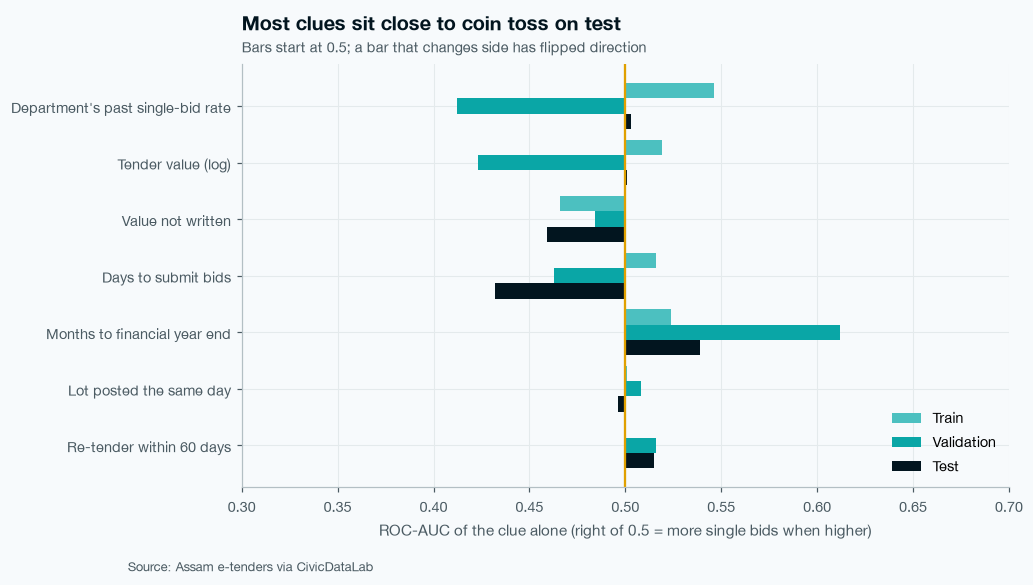

In [176]:
# Chart S7s: each clue's direction in train, validation and test
fig, ax = plt.subplots(figsize=(9, 5))
pos = np.arange(len(flip_table))
b1 = ax.barh(pos - 0.27, flip_table["train"] - 0.5, height=0.27, left=0.5, color=ts.BLUES[2], label="Train")
b2 = ax.barh(pos, flip_table["validation"] - 0.5, height=0.27, left=0.5, color=ts.BLUES[3], label="Validation")
b3 = ax.barh(pos + 0.27, flip_table["test"] - 0.5, height=0.27, left=0.5, color=ts.BLUES[5], label="Test")

# Coin-toss line in the middle, clue names, axis name, legend
ax.axvline(0.5, color=ts.SINGLE, linewidth=1.5)
ax.set_yticks(pos, flip_table["clue"])
ax.invert_yaxis()
ax.set_xlim(0.3, 0.7)
ax.set_xlabel("ROC-AUC of the clue alone (right of 0.5 = more single bids when higher)")
ax.legend(loc="lower right")

# Title, subtitle, source
subtitle = "Bars start at 0.5; a bar that changes side has flipped direction"
ts.title(ax, "Most clues sit close to coin toss on test", subtitle=subtitle)
ts.source(fig)

In [177]:
ts.save_fig(fig, "../reports/figures/S7s_clue_direction.png")

### (f) Are the High-band tenders spread across months?

In [178]:
# Share (%) of each month's tenders that land in the High band
high_rows = []
for name in month_order:
    part = test[test["month_name"] == name]
    row = {}
    row["month"] = name
    row["tenders"] = len(part)
    row["in High band %"] = round((part["band"] == "High").mean() * 100, 1)
    high_rows.append(row)
pd.DataFrame(high_rows)

,month,tenders,in High band %
0,Jan 2023,842,24.6
1,Feb 2023,485,6.8
2,Mar 2023,355,7.9
3,Apr-May 2023,85,100.0


### (g) Ranking inside each month instead of across all test months

Check (f) shows that the High band is not spread evenly across months. The clue "months to financial year end" is the same for every tender in a month, so some months get almost all the High flags.

In real life the auditor would rank each new month's tenders on their own. So here I check what happens when the top 20% is picked inside each month. This is only a check. The locked results above stay as they are.

In [179]:
# Helper 12: single-bid tenders caught when the auditor checks the riskiest 20% of EACH month
def month_top20_caught(col):
    month_share = test.groupby("month_name")[col].rank(ascending=False, pct=True, method="first")
    return int(test.loc[month_share <= 0.2, "single_bid"].sum())

In [180]:
# Caught across all months (locked) vs inside each month (check), for every method
inside_rows = []
for col in methods:
    row = {}
    row["method"] = methods[col]
    row["caught, top 20% of all test"] = int(top20(col)["single_bid"].sum())
    row["caught, top 20% of each month"] = month_top20_caught(col)
    inside_rows.append(row)
inside_table = pd.DataFrame(inside_rows)
inside_table

,method,"caught, top 20% of all test","caught, top 20% of each month"
0,Random checking,79,81
1,Rule B: re-tender then dept,108,105
2,"LogReg 7 clues, monthly",101,105
3,Embeddings alone,85,85


In [181]:
# Bands of the main model when ranked inside each month
test["month_share"] = test.groupby("month_name")["risk_main"].rank(ascending=False, pct=True, method="first")
test["month_band"] = np.where(test["month_share"] <= 0.2, "High", np.where(test["month_share"] <= 0.5, "Medium", "Low"))
month_band_table = test.groupby("month_band")["single_bid"].agg(["count", "mean"]).reindex(band_order)
month_band_table.columns = ["tenders", "single-bid %"]
month_band_table["single-bid %"] = (month_band_table["single-bid %"] * 100).round(1)
month_band_table

,tenders,single-bid %
month_band,,
High,353,29.7
Medium,529,23.8
Low,885,21.5


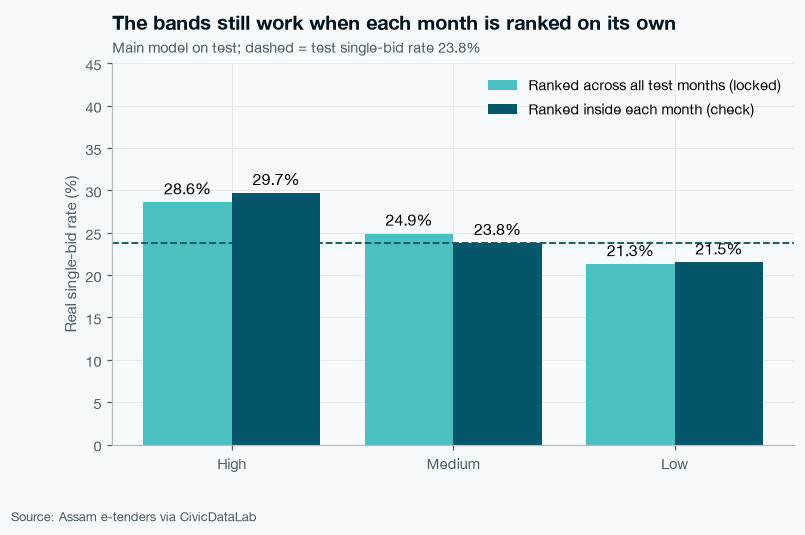

In [182]:
# Chart S7t: real single-bid rate per band, ranked across all months vs inside each month
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(band_order))
b1 = ax.bar(pos - 0.2, band_table["single-bid %"], width=0.4, color=ts.BLUES[2], label="Ranked across all test months (locked)")
b2 = ax.bar(pos + 0.2, month_band_table["single-bid %"], width=0.4, color=ts.BLUES[4], label="Ranked inside each month (check)")

# % labels, dashed test rate, group names, room, legend
ax.bar_label(b1, fmt="%.1f%%", padding=3)
ax.bar_label(b2, fmt="%.1f%%", padding=3)
ax.axhline(base_rate, color=ts.THIRD, linestyle="--", linewidth=1.2)
ax.set_xticks(pos, band_order)
ax.set_ylabel("Real single-bid rate (%)")
ax.set_ylim(0, 45)
ax.legend(loc="upper right")

# Title, subtitle, source
subtitle = "Main model on test; dashed = test single-bid rate " + str(round(base_rate, 1)) + "%"
ts.title(ax, "The bands still work when each month is ranked on its own", subtitle=subtitle)
ts.source(fig)

In [183]:
ts.save_fig(fig, "../reports/figures/S7t_bands_inside_month.png")

In [184]:
# Save the check tables too
inside_table.to_csv("../reports/s7_check_inside_month.csv", index=False)
flip_table.to_csv("../reports/s7_check_clue_direction.csv", index=False)
print("Checks saved")

Checks saved


### Insight · Extra checks (Step 23)

- (a) Counting repeated lots once (1,717 tenders) gave almost the same result: main model PR-AUC 0.254 and 23.7% found, random 0.230 and 18.6%. So copies do not create the win.
- (b) Tenders with no value written get fewer single bids in every period: train 28.7% vs 38.1%, validation 19.6% vs 28.5%, test 13.4% vs 25.6%. This is the steadiest clue I have.
- (c) Quick re-tenders got more single bids in test too (34.4% vs 23.3%), but much less than in validation (58.3%). This is why Rule B did well.
- (d) The same model learned once on 1 January did as well as the monthly one (PR-AUC 0.258 vs 0.256). So in these 5 months monthly retraining did not add much. I still keep monthly retraining for real use, because patterns change over longer times.
- (e) Clue directions: the department rate went from 0.546 (train) to 0.412 (validation, wrong way) to 0.503 (test, coin toss). Days to submit bids flipped from 0.516 to 0.432. Most clues sit close to 0.5 on test, so publish-day clues are weak.
- (f) and (g) The High band was not spread evenly: all April-May tenders were High but only 6.8% of February tenders, because of the financial-year clue. When I ranked each month on its own (how an auditor would really use it), the main model still found 105 single-bid tenders (Rule B 105, random 81), and the bands still worked: High 29.7%, Medium 23.8%, Low 21.5%. This was only a check. The locked results stay as they are.

## S7 Summary - Final model, impact and SHAP (Gate 2)

### Starting point
- I had 6,790 labelled tenders, 34 clues from S5 and text embeddings from S6. On validation no method had clearly beaten random checking.
- From S6 I had 4 candidates written down before test: random checking, Rule B, LogReg on 7 clues retrained every month (opened only) and embeddings alone.
- The test months (Jan-May 2023, 1,767 tenders) had stayed locked since S4.

### What I did
- Wrote and saved a locked plan before looking at any test answer, with 3 choices: embeddings learn from all tenders opened before 1 Jan 2023, SHAP explains the final app model, and bands are top 20% High, next 30% Medium, bottom 50% Low.
- Made test embeddings with MiniLM, and scored all 4 methods. Monthly retraining used only tenders whose bids were already opened.
- Opened the test answers once and scored everything: PR-AUC, ROC-AUC, capture, lift, precision in the top 50/100/200, and 500 bootstrap re-draws.
- Looked month by month, at the auditor's top 20% (count and rupees), the confusion table, risk bands, score vs real rate, and results by work type, category and department.
- Compared validation and test fairly (PR-AUC divided by the single-bid rate).
- Trained the final app model on all 6,790 tenders, saved it, and explained it with SHAP (overall, the top 2 clues, and five example tenders).
- Wrote a model card and did 7 extra checks.

### What I found
- Test had the fewest single-bid tenders of all periods, 23.8% (train 36.1%, validation 27.8%), and it kept falling month by month (28.5% in January to 7.1% in April-May).
- Checking the riskiest 20% (353 tenders): random checking found 79 of 421 single-bid tenders, the main model 101, Rule B 108 and embeddings 85.
- The main model beat random checking in 95.8% of 500 re-draws. This is the first real win over random in the project, but it is small (lift 1.20).
- The simple Rule B was a little better than the model, and the model did not beat it.
- Embeddings fell back to random on test, because the words keep changing.
- The risk bands are in the right order: High 28.6%, Medium 24.9%, Low 21.3%. Scores are not real percentages, so the app will show bands.
- The rupee finding from S5 did not come back: the main model's catches were worth Rs 170.0 crore vs Rs 199.5 crore for random.
- SHAP: months to financial year end and value not written move the score most. The financial-year clue only changes which month looks risky, so ranking each month on its own is the right way to use the model (still 105 found).
- The results stayed the same when repeated lots were counted once.

### Files saved
- reports: s7_locked_plan.csv, s7_test_results.csv, s7_bootstrap.csv, s7_month_table.csv, s7_auditor_view.csv, s7_risk_bands.csv, s7_val_vs_test.csv, s7_by_work_type.csv, s7_by_category.csv, s7_by_department.csv, s7_test_predictions.csv, s7_shap_test.csv, s7_example_tenders.csv, s7_check_inside_month.csv, s7_check_clue_direction.csv, s7_model_card.md
- data/processed: s7_embeddings_test.npy
- models: tenderlens_logreg.joblib, tenderlens_scaler.joblib, tenderlens_clues.csv, tenderlens_band_cutoffs.csv
- reports/figures: S7a to S7t (24 charts)

### Next steps
- S8: anomaly and patterns (Isolation Forest, award ratio, supplier concentration, rupee value at risk).
- S10 app: rank each month's tenders on their own and show High, Medium or Low with the SHAP reasons. Also think about showing the quick re-tender flag, because it was the strongest simple signal.
- For the presentation: a small but real win over random, a strong simple rule, and patterns that keep changing over time.